# 🐦 Bird Species Detection — eBird + iNaturalist → YOLO → Live Stream

A single-file pipeline that:

1. Pulls an **active species list** from the eBird API for your region
2. Downloads **research-grade photos** from the iNaturalist API and auto-labels them
3. Builds a proper YOLO dataset and **trains** a species model
4. Runs **live detection** on a YouTube stream with an inline video view
5. Logs detections to **SQLite** and renders an analytics dashboard

## How to drive it

Everything you would ever want to change lives in **the Control Panel (cell 3)**.
Nothing below it needs editing. The `RUN_*` switches let you skip stages you have
already completed, so a second run can go straight to streaming:

```python
RUN_FETCH_SPECIES = False   # already cached
RUN_DOWNLOAD      = False   # dataset already on disk
RUN_TRAIN         = False   # weights already trained
RUN_LIVE          = True    # just watch the birds
```


In [18]:
# ============================================================================
#  0. INSTALL & IMPORTS
# ============================================================================
# Set to True the first time you run this in a fresh kernel / container.
INSTALL_DEPS = False

if INSTALL_DEPS:
    %pip install -q ultralytics opencv-python-headless yt-dlp requests tqdm pillow pyyaml pandas matplotlib ipywidgets

import os
import sys
import json
import time
import shutil
import random
import sqlite3
import logging
import threading
from queue import Queue, Empty
from pathlib import Path
from datetime import datetime
from collections import defaultdict, deque

import cv2
import yaml
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from PIL import Image
from ultralytics import YOLO

from IPython.display import display, HTML, Image as IPyImage

# ipywidgets gives the smoothest live view; we degrade gracefully without it.
try:
    import ipywidgets as widgets
    HAVE_WIDGETS = True
except ImportError:
    widgets = None
    HAVE_WIDGETS = False

# ---------------------------------------------------------------------------
# OpenCV reads video through FFmpeg. Both of these are consulted when a capture
# is opened, so they have to be in place before the live cell runs.
#
# reconnect*  A long-lived googlevideo connection gets closed by the far end
#             after a few minutes — that is the "[tls @ ...] IO error: End of
#             file" you will otherwise see. Without these, OpenCV simply starts
#             failing reads and the notebook's own reconnect takes a couple of
#             seconds to notice. With them, FFmpeg reopens the HTTP connection
#             underneath and the frames never stop. reconnect_streamed is the
#             one that matters: a live stream is not seekable, and plain
#             reconnect will not retry it.
#
# LOGLEVEL    Those messages are written from C straight to stderr, so Python
#             logging cannot filter them. 8 = fatal only, -8 = silent,
#             24 = warnings and up. Fatal is the default here because the
#             notebook reports stream trouble itself, in the live stats panel
#             and the session summary. Raise it to 24 when something is wrong
#             and you want FFmpeg's own account of it.
#
# setdefault, not assignment: anything you exported outside the notebook wins.
os.environ.setdefault(
    "OPENCV_FFMPEG_CAPTURE_OPTIONS",
    "reconnect;1|reconnect_streamed;1|reconnect_on_network_error;1"
    "|reconnect_delay_max;5",
)
os.environ.setdefault("OPENCV_FFMPEG_LOGLEVEL", "8")

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s  %(levelname)-7s %(message)s",
    datefmt="%H:%M:%S",
)
log = logging.getLogger("birdcam")
logging.getLogger("ultralytics").setLevel(logging.WARNING)

%matplotlib inline

import torch
import platform
import ultralytics


def env_report():
    """
    Report the environment, and be specific about WHY CUDA is missing.

    On DGX Spark this matters more than usual: the default pip wheel for
    aarch64 is CPU-only, so `pip install ultralytics` quietly gives you a
    PyTorch that cannot see the GB10 at all. Training then runs on the Arm
    cores at roughly 1-2% of GPU speed, with no error to tell you.
    """
    arch = platform.machine()
    cuda_build = torch.version.cuda          # None => CPU-only wheel
    available = torch.cuda.is_available()

    print(f"Python      : {sys.version.split()[0]}  ({arch})")
    print(f"PyTorch     : {torch.__version__}   built against CUDA: {cuda_build or 'NONE (cpu-only wheel)'}")
    print(f"Ultralytics : {ultralytics.__version__}")
    print(f"OpenCV      : {cv2.__version__}")
    print(f"ipywidgets  : {'yes' if HAVE_WIDGETS else 'no (falling back to still-frame display)'}")

    if available:
        name = torch.cuda.get_device_name(0)
        cap = torch.cuda.get_device_capability(0)
        print(f"GPU         : ✓ {name}  (sm_{cap[0]}{cap[1]})")
        if cap == (12, 1):
            print("              note: a 'cuda capability 12.1 not supported' UserWarning")
            print("              on GB10 is cosmetic — kernels still run. Ignore it.")
        return True

    print("GPU         : ✗ torch.cuda.is_available() is False — TRAINING WILL USE CPU")
    print()
    if cuda_build is None:
        print("  Diagnosis: your PyTorch wheel has no CUDA in it at all.")
        if arch == "aarch64":
            print("  On ARM64 (DGX Spark / Jetson) the default PyPI wheel is CPU-only,")
            print("  which is almost certainly what pip installed alongside ultralytics.")
            print()
            print("  Fix — install the CUDA 13 aarch64 build over the top:")
            print("      pip install torch torchvision --index-url https://download.pytorch.org/whl/cu130")
            print()
            print("  Then RESTART THE KERNEL. Ultralytics' own DGX Spark guide has the")
            print("  full sequence: https://docs.ultralytics.com/guides/nvidia-dgx-spark")
        else:
            print("  Fix: reinstall PyTorch from the CUDA index for your platform,")
            print("  then restart the kernel.  https://pytorch.org/get-started/locally/")
    else:
        print(f"  Diagnosis: PyTorch has CUDA {cuda_build} compiled in, but no device is")
        print("  visible. That points at the driver or the container, not the wheel.")
        print("    • bare metal → run `nvidia-smi`; if that fails, the driver is the problem")
        print("    • docker     → needs `--device nvidia.com/gpu=all` on DGX OS,")
        print("                   or `--runtime=nvidia` on Jetson/JetPack")
    print()
    return False


CUDA_OK = env_report()


Python      : 3.11.6  (aarch64)
PyTorch     : 2.12.1+cu130   built against CUDA: 13.0
Ultralytics : 8.4.78
OpenCV      : 4.13.0
ipywidgets  : yes
GPU         : ✓ NVIDIA GB10  (sm_121)
              note: a 'cuda capability 12.1 not supported' UserWarning
              on GB10 is cosmetic — kernels still run. Ignore it.


In [19]:
# ============================================================================
#  1. ⚙️  CONTROL PANEL  — the only cell you should ever need to edit
# ============================================================================

# ---------------------------------------------------------------- pipeline --
# You no longer flip five booleans by hand. Each stage inspects what is
# already on disk and skips itself when that work is done AND still matches
# the settings below. Run All on a warm project goes straight to the live
# view in seconds: nothing re-downloaded, nothing re-trained.
#
#   "auto"  -> skip any stage whose output exists and is still valid
#   "force" -> rebuild everything, ignoring what is on disk
#   "ask"   -> like auto, but prompt before each skip
#
PIPELINE_MODE = "auto"

# Per-stage overrides. Names: species | download | dataset | train | live
FORCE_STAGES = set()        # e.g. {"train"} -> retrain even though best.pt exists
SKIP_STAGES  = set()        # e.g. {"live"}  -> never run, even if it would

# Age-based invalidation. None = never expire on age alone.
SPECIES_CACHE_MAX_AGE_DAYS = 30     # eBird list drifts with the seasons
MODEL_MAX_AGE_DAYS         = None   # weights do not rot; set a number if you
                                    # want a periodic refresh anyway

# ------------------------------------------------------------------ paths --
# Every artifact lives under this one root. Change it and the whole tree moves.
PROJECT_ROOT = Path("bird_project")

# ------------------------------------------------------------- API access --
# Read from the environment if present, otherwise paste yours below.
# Get a key at https://ebird.org/api/keygen
# The environment wins, so a copy of this notebook handed to somebody else
# does not ship your key with it. eBird rate-limits per key — a class all
# using the same one will throttle each other.
EBIRD_FALLBACK_KEY = "YOURKEY"
EBIRD_API_KEY = os.environ.get("EBIRD_API_KEY", EBIRD_FALLBACK_KEY)

# iNaturalist asks that API clients identify themselves. Put a real contact in.
INAT_USER_AGENT = "BirdYOLO/1.0 (educational research; contact: jtalbott@kent.edu)"

# ----------------------------------------------------------- which birds? --
# "ebird"  -> most-reported species in EBIRD_REGION over the last N days
# "manual" -> exactly the SPECIES_MANUAL list below, nothing else
SPECIES_MODE = "ebird"

EBIRD_REGION      = "US"   # US | US-OH | US-NY | CA | GB | ...
EBIRD_DAYS_BACK   = 30        # observation window (1-30)
MAX_SPECIES       = 10        # class count. 8-15 trains well; 50 does not.

SPECIES_MANUAL = [
    "Northern Cardinal",
    "Blue Jay",
    "American Robin",
    "Mourning Dove",
    "Black-capped Chickadee",
    "American Goldfinch",
    "Downy Woodpecker",
    "Tufted Titmouse",
    "White-breasted Nuthatch",
    "House Finch",
]

# ------------------------------------------------------- dataset building --
IMAGES_PER_SPECIES     = 60      # target photos per species (50-150 is sane)
MIN_IMAGES_PER_SPECIES = 12      # below this the species is dropped entirely
INAT_LICENSED_ONLY     = True    # only CC-licensed photos (respects photographers)
INAT_PHOTO_SIZE        = "medium"  # square | small | medium | large | original
INAT_REQUEST_PAUSE     = 1.0     # seconds between API calls (iNat asks <= 60/min)

# Auto-labelling uses a stock COCO YOLO to find the bird inside each photo.
# yolo26n is current; yolo11n / yolov8n also work and are smaller downloads.
AUTOLABEL_MODEL     = "yolo26n.pt"
AUTOLABEL_CONF      = 0.30
REQUIRE_BIRD_BOX    = True   # True  -> discard photos where no bird was found
                             # False -> fall back to a full-frame box (trains worse)
VAL_SPLIT           = 0.2

# ----------------------------------------------------------------- training --
TRAIN_BASE_MODEL = "yolo26n.pt"   # n < s < m < l < x  (bigger = slower, better)
ALLOW_CPU_TRAIN  = False          # True to train on CPU anyway. On a GB10 that
                                  # is ~50-100x slower — the guard exists so a
                                  # broken CUDA install fails loudly, not slowly.
TRAIN_EPOCHS     = 60
TRAIN_IMGSZ      = 640
TRAIN_BATCH      = 16             # -1 lets Ultralytics autotune to your VRAM
TRAIN_PATIENCE   = 15             # early-stop after N epochs with no improvement
TRAIN_RUN_NAME   = "birds_v1"     # bump this for a new run instead of overwriting

# Throughput, not correctness. If GPU utilisation sits low and epochs crawl,
# you are dataloader-bound, not compute-bound — which looks exactly like CPU
# training from the outside. With 128 GB unified memory, caching the whole
# dataset in RAM removes that bottleneck entirely.
TRAIN_CACHE      = "ram"          # "ram" | "disk" | False
TRAIN_WORKERS    = 8              # dataloader workers; drop to 0 if memory bites

# ------------------------------------------------------------------ stream --
YOUTUBE_VIDEO_ID = "x10vL6_47Dw"   # Cornell Lab feeder cam
# Or point at any file / RTSP / HTTP source and skip YouTube entirely:
STREAM_URL_OVERRIDE = None         # e.g. "rtsp://..." or "/path/to/clip.mp4"

STREAM_MAX_HEIGHT  = 720   # cap the pulled resolution; 1080p costs bandwidth
                           # and decode time for no detection benefit here
STREAM_RECONNECT   = True  # googlevideo URLs expire — re-resolve and reopen
STREAM_STALL_LIMIT = 50    # failed reads before triggering a reconnect

# --------------------------------------------------------------- inference --
# Leave as None to auto-discover the newest trained weights, else force a path.
MODEL_PATH_OVERRIDE = None

CONF_THRESHOLD = 0.35   # raise to cut false positives, lower to catch more
IOU_THRESHOLD  = 0.45
INFER_IMGSZ    = 640

# ------------------------------------------------------------- live viewer --
LIVE_REFRESH_FPS  = 4.0    # detect+redraw cycles per second. THIS is your knob.
LIVE_MAX_MINUTES  = 5      # auto-stop. Interrupt the kernel to stop early.
LIVE_DISPLAY_W    = 960    # on-screen width in px (does not affect inference)
LIVE_JPEG_QUALITY = 80
LIVE_SHOW_EMPTY   = True   # True: always show video. False: only redraw on a hit.

# How the video gets drawn in the notebook.
#
#   "still"   Replaces a display handle each frame. Works in JupyterLab,
#             Notebook 7, VS Code and Colab with nothing installed. The
#             default, because a view that always works beats one that is
#             smoother once configured — and at 4 fps you cannot tell.
#   "widget"  ipywidgets. Smoother, but needs a matching frontend extension.
#             When that is missing it does not raise: it prints
#             VBox(children=(Image(value=b'', ...))) and shows no video at all.
#   "auto"    Use the widget only when the frontend packages are installed.
#
LIVE_VIEW = "still"

# ------------------------------------------------------------ stream out --
# Broadcast the annotated frames — boxes and species labels burned in — so
# something other than this notebook can watch them. Pick one or several.
#
#   "mjpeg"  JPEGs over HTTP. Opens in any browser, no ffmpeg, no player
#            library, latency = one inference interval. Best default.
#   "hls"    ffmpeg -> H.264 -> segments on disk + a static server. 3-6s
#            behind, but efficient for many viewers and leaves a recording.
#   "rtmp"   ffmpeg -> YouTube / Twitch / anything that speaks RTMP.
#   "rtsp"   ffmpeg -> a media server (MediaMTX) that republishes as WebRTC.
#
STREAM_OUT     = ["mjpeg"]   # [] or ["off"] to disable entirely
STREAM_OUT_FPS = 10          # cadence handed to viewers. Frames are duplicated
                             # when inference is slower than this, so the rate
                             # ffmpeg is told is the rate it actually gets.

MJPEG_PORT    = 8089
MJPEG_QUALITY = 75
MJPEG_BIND    = "0.0.0.0"    # "127.0.0.1" to keep it on this machine only

HLS_DIR             = None   # defaults to bird_project/stream/
HLS_PORT            = 8090
HLS_SEGMENT_SECONDS = 1
HLS_WINDOW          = 8      # segments kept in the playlist

RTMP_URL = None              # "rtmp://a.rtmp.youtube.com/live2/<stream-key>"
RTSP_URL = None              # "rtsp://127.0.0.1:8554/birds"  (MediaMTX)

FFMPEG_BIN     = "ffmpeg"
FFMPEG_ENCODER = "libx264"   # 720p at 10 fps is nothing for a CPU. Check
                             # `ffmpeg -encoders | grep nvenc` before reaching
                             # for h264_nvenc — the args differ and this cell
                             # adapts, but only for encoders it recognises.
FFMPEG_PRESET  = "veryfast"
FFMPEG_CRF     = 23

# --------------------------------------------------------- how much to save --
# A feeder cam at 4 fps would write ~14k rows an hour unthrottled. These caps
# keep the database and the frames folder to something you can actually read.
DB_ENABLED             = True
DB_COOLDOWN_SECONDS    = 5.0    # per species: ignore repeats inside this window
DB_MIN_CONFIDENCE      = 0.40   # only log detections you would trust

SAVE_FRAMES            = True
FRAME_COOLDOWN_SECONDS = 30.0   # at most one saved frame per this many seconds
FRAME_MAX_FILES        = 60     # oldest frames are pruned past this count

# ============================================================================
print("Control panel loaded.")
print(f"  species mode : {SPECIES_MODE}" + (f" ({EBIRD_REGION}, top {MAX_SPECIES})" if SPECIES_MODE == "ebird" else f" ({len(SPECIES_MANUAL)} listed)"))
print(f"  pipeline     : {PIPELINE_MODE}"
      + (f"  force={sorted(FORCE_STAGES)}" if FORCE_STAGES else "")
      + (f"  skip={sorted(SKIP_STAGES)}" if SKIP_STAGES else ""))
print(f"  live         : {LIVE_REFRESH_FPS} fps for up to {LIVE_MAX_MINUTES} min")
print(f"  stream out   : {', '.join(STREAM_OUT) or 'off'}"
      + (f" at {STREAM_OUT_FPS} fps" if STREAM_OUT and STREAM_OUT != ['off'] else ""))
_warnings = []
if not EBIRD_API_KEY and SPECIES_MODE == "ebird":
    _warnings.append("No eBird key. Set the EBIRD_API_KEY environment variable "
                     "(free at https://ebird.org/api/keygen)\n     or switch "
                     "SPECIES_MODE to 'manual'.")
elif EBIRD_API_KEY == EBIRD_FALLBACK_KEY and SPECIES_MODE == "ebird":
    _warnings.append("Using the key written into this notebook. Fine for one "
                     "person; get your own before\n     sharing this, or eBird "
                     "will rate-limit everyone using it together.")
if "you@example.edu" in INAT_USER_AGENT:
    _warnings.append("INAT_USER_AGENT still says you@example.edu. iNaturalist "
                     "asks API clients to\n     identify themselves — put a "
                     "real contact in before downloading at any scale.")
for _w in _warnings:
    print(f"\n  ⚠  {_w}")


Control panel loaded.
  species mode : ebird (US, top 10)
  pipeline     : auto
  live         : 4.0 fps for up to 5 min
  stream out   : mjpeg at 10 fps

  ⚠  Using the key written into this notebook. Fine for one person; get your own before
     sharing this, or eBird will rate-limit everyone using it together.


In [20]:
# ============================================================================
#  2. FOLDER LAYOUT  — everything derived from PROJECT_ROOT, nothing hardcoded
# ============================================================================
#
#   bird_project/
#   ├── cache/              species list + resolved iNat taxon ids
#   ├── dataset/
#   │   ├── raw/            downloaded originals, one folder per species
#   │   │   └── <species>/  photos + _attribution.csv
#   │   └── yolo/           the training set YOLO actually reads
#   │       ├── images/{train,val}/
#   │       ├── labels/{train,val}/
#   │       └── data.yaml
#   ├── runs/               Ultralytics training output
#   ├── models/             best.pt copied here after each successful train
#   ├── captures/           annotated frames from the live run
#   └── db/detections.sqlite
#
# ============================================================================

ROOT       = PROJECT_ROOT.resolve()
CACHE_DIR  = ROOT / "cache"
RAW_DIR    = ROOT / "dataset" / "raw"
YOLO_DIR   = ROOT / "dataset" / "yolo"
IMG_DIR    = YOLO_DIR / "images"
LBL_DIR    = YOLO_DIR / "labels"
RUNS_DIR   = ROOT / "runs"
MODELS_DIR = ROOT / "models"
CAPTURE_DIR = ROOT / "captures"
DB_DIR     = ROOT / "db"

DATA_YAML   = YOLO_DIR / "data.yaml"
SPECIES_CACHE = CACHE_DIR / "species.json"
TAXA_CACHE    = CACHE_DIR / "inat_taxa.json"
BEST_WEIGHTS  = MODELS_DIR / "best.pt"
DB_PATH       = DB_DIR / "detections.sqlite"

for d in (CACHE_DIR, RAW_DIR, RUNS_DIR, MODELS_DIR, CAPTURE_DIR, DB_DIR,
          IMG_DIR / "train", IMG_DIR / "val",
          LBL_DIR / "train", LBL_DIR / "val"):
    d.mkdir(parents=True, exist_ok=True)


def slugify(name: str) -> str:
    """'Black-capped Chickadee' -> 'black_capped_chickadee' (filesystem-safe)."""
    keep = "".join(c if (c.isalnum() or c in " -_") else "" for c in name)
    return keep.strip().lower().replace("-", "_").replace(" ", "_")


def dir_report(root: Path = ROOT) -> None:
    """Print what is actually on disk right now — sizes, counts, staleness."""
    def count(p, pat="*"):
        return len(list(p.glob(pat))) if p.exists() else 0

    raw_species = sorted(d for d in RAW_DIR.iterdir() if d.is_dir()) if RAW_DIR.exists() else []
    raw_photos  = sum(count(d, "*.jpg") for d in raw_species)

    print(f"📁 {root}")
    print(f"   raw dataset   : {len(raw_species)} species, {raw_photos} photos")
    print(f"   yolo train    : {count(IMG_DIR / 'train', '*.jpg')} images")
    print(f"   yolo val      : {count(IMG_DIR / 'val', '*.jpg')} images")
    print(f"   data.yaml     : {'yes' if DATA_YAML.exists() else 'not built yet'}")
    print(f"   trained model : {'yes -> ' + str(BEST_WEIGHTS) if BEST_WEIGHTS.exists() else 'not trained yet'}")
    print(f"   captures      : {count(CAPTURE_DIR, '*.jpg')} frames")
    if DB_PATH.exists():
        size_kb = DB_PATH.stat().st_size / 1024
        try:
            with sqlite3.connect(DB_PATH) as c:
                rows = c.execute("SELECT COUNT(*) FROM detections").fetchone()[0]
            print(f"   database      : {rows} detections ({size_kb:.0f} KB)")
        except sqlite3.Error:
            print(f"   database      : present but no table yet ({size_kb:.0f} KB)")
    else:
        print("   database      : not created yet")


dir_report()


📁 /home/jovyan/bird_project
   raw dataset   : 30 species, 1800 photos
   yolo train    : 1440 images
   yolo val      : 360 images
   data.yaml     : yes
   trained model : yes -> /home/jovyan/bird_project/models/best.pt
   captures      : 35 frames
   database      : 224 detections (52 KB)


In [21]:
# ============================================================================
#  2b. STAGE GATES  — decide what actually needs doing this run
# ============================================================================
# Every expensive stage asks gate() before it runs. The answer comes from what
# is on disk, not from a boolean you have to remember to flip. Three rules
# worth knowing:
#
#   * a stage is only skipped if its output is *valid for the current
#     settings* — change MAX_SPECIES or TRAIN_BASE_MODEL and the affected
#     stages come back on by themselves
#   * every decision prints its reason, so a surprise skip is never silent
#   * PIPELINE_MODE = "force" ignores all of this and rebuilds
#
# The stage this matters most for is `download`. It loads a stock COCO model
# to auto-label with, and loading it is what pulls a checkpoint off the
# internet mid-notebook. Gate the stage and that download never happens.
# ============================================================================

BEST_META      = MODELS_DIR / "best.meta.json"
DOWNLOAD_STATE = CACHE_DIR / "download_state.json"

_GATE_LOG = {}


def _age_days(path: Path) -> float:
    return (time.time() - path.stat().st_mtime) / 86400


def _read_json(path: Path, default=None):
    try:
        return json.loads(path.read_text())
    except (OSError, json.JSONDecodeError):
        return default


def gate(stage: str, check) -> bool:
    """
    check is (done, reason). Returns True if the stage should run.

    `reason` explains the decision either way — when done it says what is
    being reused, when not done it says what is missing.
    """
    done, reason = check
    if stage in SKIP_STAGES:
        run, why = False, "in SKIP_STAGES"
    elif PIPELINE_MODE == "force" or stage in FORCE_STAGES:
        run, why = True, "forced"
    elif not done:
        run, why = True, reason or "nothing reusable on disk"
    elif PIPELINE_MODE == "ask":
        answer = input(f"  {stage}: {reason}.  Run it again anyway? [y/N] ")
        run = answer.strip().lower().startswith("y")
        why = "you said yes" if run else reason
    else:
        run, why = False, reason

    _GATE_LOG[stage] = (run, why)
    print(f"{'RUN  ▶' if run else 'SKIP ✓'}  {stage:<9} {why}")
    return run


# ---------------------------------------------------------------- checks ----

def species_cached() -> tuple:
    if not SPECIES_CACHE.exists():
        return False, "no cached species list"
    cached = _read_json(SPECIES_CACHE)
    if not cached:
        return False, "species cache is empty or corrupt"
    if len(cached) < MAX_SPECIES and SPECIES_MODE == "ebird":
        return False, f"cache has {len(cached)} species, MAX_SPECIES is now {MAX_SPECIES}"
    age = _age_days(SPECIES_CACHE)
    if SPECIES_CACHE_MAX_AGE_DAYS and age > SPECIES_CACHE_MAX_AGE_DAYS:
        return False, f"cache is {age:.0f} days old (limit {SPECIES_CACHE_MAX_AGE_DAYS})"
    return True, f"{len(cached)} species cached, {age:.1f}d old"


def photos_ready(species: list) -> tuple:
    """A photo counts only if it has a label sidecar next to it."""
    counts = {}
    for name in species:
        d = RAW_DIR / slugify(name)
        counts[name] = (sum(1 for p in d.glob("*.jpg") if (d / f"{p.stem}.txt").exists())
                        if d.exists() else 0)
    total = sum(counts.values())
    stocked = sum(1 for c in counts.values() if c >= MIN_IMAGES_PER_SPECIES)

    if not total:
        return False, "no labelled photos in dataset/raw/"

    state = _read_json(DOWNLOAD_STATE, {}) or {}
    missing = [n for n in species if n not in state.get("species", [])]
    if missing:
        shown = ", ".join(missing[:3]) + ("…" if len(missing) > 3 else "")
        return False, f"{len(missing)} species never downloaded ({shown})"
    if state.get("images_per_species", 0) < IMAGES_PER_SPECIES:
        return False, (f"last pass targeted {state.get('images_per_species')} photos/species, "
                       f"you now want {IMAGES_PER_SPECIES}")
    if state.get("require_bird_box") != REQUIRE_BIRD_BOX:
        return False, "REQUIRE_BIRD_BOX changed since the last download"
    if state.get("licensed_only") != INAT_LICENSED_ONLY:
        return False, "INAT_LICENSED_ONLY changed since the last download"

    # A previous pass already asked iNaturalist for everything it had. Species
    # still short of the target are short because the photos do not exist —
    # re-running would just re-ask and get the same answer.
    return True, f"{total} labelled photos, {stocked}/{len(species)} species above minimum"


def dataset_ready() -> tuple:
    if not DATA_YAML.exists():
        return False, "no data.yaml yet"
    cfg = None
    try:
        cfg = yaml.safe_load(DATA_YAML.read_text())
    except Exception:
        pass
    if not isinstance(cfg, dict) or "names" not in cfg:
        return False, "data.yaml is unreadable"
    n_train = len(list((IMG_DIR / "train").glob("*.jpg")))
    n_val = len(list((IMG_DIR / "val").glob("*.jpg")))
    if not n_train or not n_val:
        return False, f"split is empty (train {n_train}, val {n_val})"
    if len(cfg["names"]) != int(cfg.get("nc", -1)):
        return False, "data.yaml nc disagrees with its own names list"
    newest_raw = max((p.stat().st_mtime for p in RAW_DIR.rglob("*.jpg")), default=0)
    if newest_raw > DATA_YAML.stat().st_mtime:
        return False, "photos were downloaded after the split was built"
    return True, f"{cfg['nc']} classes, {n_train} train / {n_val} val"


def dataset_class_names() -> list:
    cfg = yaml.safe_load(DATA_YAML.read_text()) if DATA_YAML.exists() else {}
    return list(cfg.get("names", [])) if isinstance(cfg, dict) else []


def _adopt_existing_weights():
    """
    First run after this upgrade: there is a best.pt but no sidecar describing
    it. Read the class names straight out of the checkpoint and write the
    sidecar, so this only ever costs one model load.
    """
    try:
        names = YOLO(str(BEST_WEIGHTS)).names
    except Exception as exc:
        log.warning(f"Could not read {BEST_WEIGHTS}: {exc}")
        return None
    meta = {
        "names": [names[k] for k in sorted(names)],
        "base_model": TRAIN_BASE_MODEL,
        "epochs": None,
        "map50": None,
        "adopted": True,
        "saved_at": datetime.fromtimestamp(BEST_WEIGHTS.stat().st_mtime).isoformat(timespec="seconds"),
    }
    BEST_META.write_text(json.dumps(meta, indent=2))
    return meta


def model_ready() -> tuple:
    if MODEL_PATH_OVERRIDE:
        return True, f"MODEL_PATH_OVERRIDE points at {MODEL_PATH_OVERRIDE}"
    if not BEST_WEIGHTS.exists():
        return False, "no trained weights in models/"
    age = _age_days(BEST_WEIGHTS)
    if MODEL_MAX_AGE_DAYS and age > MODEL_MAX_AGE_DAYS:
        return False, f"weights are {age:.0f} days old (limit {MODEL_MAX_AGE_DAYS})"

    meta = _read_json(BEST_META) or _adopt_existing_weights()
    if meta is None:
        return False, "weights present but the checkpoint would not load"

    want, have = dataset_class_names(), meta.get("names", [])
    if want and have != want:
        gone = sorted(set(want) - set(have))
        detail = f" — dataset adds {', '.join(gone[:3])}" if gone else ""
        return False, f"weights cover {len(have)} classes, dataset has {len(want)}{detail}"
    if meta.get("base_model") != TRAIN_BASE_MODEL:
        return False, f"trained from {meta.get('base_model')}, panel now says {TRAIN_BASE_MODEL}"

    score = f", mAP50 {meta['map50']:.3f}" if meta.get("map50") else ""
    return True, f"{len(have)} classes, trained {age:.1f}d ago{score}"


print("Stage gates armed.")
print(f"  mode        : {PIPELINE_MODE}")
print(f"  model meta  : {BEST_META if BEST_META.exists() else '(none yet)'}")


Stage gates armed.
  mode        : auto
  model meta  : /home/jovyan/bird_project/models/best.meta.json


In [22]:
# ============================================================================
#  3. SPECIES LIST  (eBird API v2, cached)
# ============================================================================

def fetch_ebird_species(region: str, days_back: int, limit: int) -> list:
    """
    Recently reported species in a region.

    Note on the endpoint: /data/obs/{region}/recent returns the *most recent
    record per species*, so every species appears exactly once and the list is
    ordered by recency, not abundance. That is fine for "what is around right
    now", but for a specific feeder cam a hand-picked SPECIES_MANUAL list will
    almost always train better — you get the 10 birds actually on camera
    instead of 12 that merely share a state with it.
    """
    resp = requests.get(
        f"https://api.ebird.org/v2/data/obs/{region}/recent",
        headers={"X-eBirdApiToken": EBIRD_API_KEY, "Accept": "application/json"},
        params={"back": days_back, "maxResults": 10000, "sppLocale": "en"},
        timeout=20,
    )
    resp.raise_for_status()
    seen, out = set(), []
    for obs in resp.json():
        name = obs.get("comName")
        if name and name not in seen:
            seen.add(name)
            out.append(name)
    return out[:limit]


def get_species_list() -> list:
    if SPECIES_MODE == "manual":
        species = list(dict.fromkeys(SPECIES_MANUAL))[:MAX_SPECIES]
        log.info(f"Using manual species list ({len(species)} species)")
        return species

    if not EBIRD_API_KEY:
        log.warning("No eBird API key — falling back to SPECIES_MANUAL")
        return list(dict.fromkeys(SPECIES_MANUAL))[:MAX_SPECIES]

    try:
        species = fetch_ebird_species(EBIRD_REGION, EBIRD_DAYS_BACK, MAX_SPECIES)
        log.info(f"eBird returned {len(species)} species for {EBIRD_REGION}")
        return species
    except Exception as exc:
        log.error(f"eBird request failed ({exc}) — falling back to SPECIES_MANUAL")
        return list(dict.fromkeys(SPECIES_MANUAL))[:MAX_SPECIES]


RUN_FETCH_SPECIES = gate("species", species_cached())

if RUN_FETCH_SPECIES:
    SPECIES = get_species_list()
    SPECIES_CACHE.write_text(json.dumps(SPECIES, indent=2))
elif SPECIES_CACHE.exists():
    SPECIES = json.loads(SPECIES_CACHE.read_text())
    log.info(f"Loaded {len(SPECIES)} species from cache")
else:
    SPECIES = list(dict.fromkeys(SPECIES_MANUAL))[:MAX_SPECIES]
    log.warning("No cache found — using SPECIES_MANUAL")

print(f"\n{len(SPECIES)} target species:")
for i, s in enumerate(SPECIES):
    print(f"  {i:2d}  {s}")


17:02:46  INFO    Loaded 20 species from cache


SKIP ✓  species   20 species cached, 11.9d old

20 target species:
   0  Bald Eagle
   1  Cooper's Hawk
   2  Common Eider
   3  Great Black-backed Gull
   4  Wood Stork
   5  Swallow-tailed Kite
   6  Black Vulture
   7  Great Egret
   8  Fish Crow
   9  Tricolored Heron
  10  Laughing Gull
  11  White Ibis
  12  Merlin
  13  Red-breasted Nuthatch
  14  Great Blue Heron
  15  Barn Swallow
  16  Roseate Spoonbill
  17  Rock Pigeon
  18  Black-capped Chickadee
  19  Mallard


In [23]:
# ============================================================================
#  4. DOWNLOAD + AUTO-LABEL  (iNaturalist API)
# ============================================================================
# Per species we write:
#     dataset/raw/<slug>/<slug>_<obs>_<n>.jpg     the photo
#     dataset/raw/<slug>/<slug>_<obs>_<n>.txt     box(es) as "xc yc w h"
#     dataset/raw/<slug>/_attribution.csv         photographer + licence
#
# The sidecar deliberately holds NO class index. Indices are assigned later,
# in the dataset build, from the species that actually survived the download.
# That is what stops you ending up with nc=50 and 40 empty classes.
# ============================================================================

INAT_HEADERS = {"User-Agent": INAT_USER_AGENT, "Accept": "application/json"}
CC_LICENCES = "cc0,cc-by,cc-by-nc,cc-by-sa,cc-by-nc-sa"


def _inat_get(url, params, retries=3):
    for attempt in range(retries):
        try:
            r = requests.get(url, params=params, headers=INAT_HEADERS, timeout=25)
            if r.status_code == 429:          # rate limited — back off and retry
                time.sleep(5 * (attempt + 1))
                continue
            r.raise_for_status()
            return r.json()
        except requests.RequestException:
            if attempt == retries - 1:
                raise
            time.sleep(2 * (attempt + 1))
    return None


def resolve_taxon_id(common_name: str, cache: dict):
    """Common name -> iNat taxon id. Far more reliable than taxon_name= search."""
    if common_name in cache:
        return cache[common_name]
    data = _inat_get(
        "https://api.inaturalist.org/v1/taxa",
        {"q": common_name, "rank": "species", "is_active": "true", "per_page": 5},
    )
    taxon_id = None
    for result in (data or {}).get("results", []):
        if result.get("iconic_taxon_name") == "Aves":     # birds only
            taxon_id = result["id"]
            break
    cache[common_name] = taxon_id
    time.sleep(INAT_REQUEST_PAUSE)
    return taxon_id


def fetch_photo_urls(taxon_id: int, want: int) -> list:
    """Return [(obs_id, photo_url, attribution, licence), ...] up to `want`."""
    collected, page = [], 1
    while len(collected) < want and page <= 5:
        params = {
            "taxon_id": taxon_id,
            "quality_grade": "research",
            "photos": "true",
            "order_by": "votes",           # community-favourite shots first
            "per_page": 100,
            "page": page,
        }
        if INAT_LICENSED_ONLY:
            params["photo_license"] = CC_LICENCES
        data = _inat_get("https://api.inaturalist.org/v1/observations", params)
        results = (data or {}).get("results", [])
        if not results:
            break
        for obs in results:
            for photo in obs.get("photos", []):
                licence = photo.get("license_code")
                if INAT_LICENSED_ONLY and not licence:
                    continue
                url = (photo.get("url") or "").replace("square", INAT_PHOTO_SIZE)
                if not url:
                    continue
                collected.append((obs["id"], url,
                                  photo.get("attribution", ""), licence or "all-rights-reserved"))
                if len(collected) >= want:
                    break
            if len(collected) >= want:
                break
        page += 1
        time.sleep(INAT_REQUEST_PAUSE)
    return collected


def bird_class_id(model: YOLO):
    """
    Index of the 'bird' class in a stock COCO model.

    It is 14 in every COCO release so far, but hardcoding an integer breaks
    silently the day that changes — you get zero labels and no explanation.
    Look it up by name instead.
    """
    for idx, label in model.names.items():
        if str(label).lower() == "bird":
            return int(idx)
    raise RuntimeError(
        f"No 'bird' class in {AUTOLABEL_MODEL} (found {len(model.names)} classes). "
        "AUTOLABEL_MODEL must be a COCO-pretrained model, not a custom one."
    )


def autolabel(labeler: YOLO, img_path: Path, bird_id: int) -> list:
    """Find bird boxes with stock YOLO. Returns [(xc, yc, w, h), ...] normalised."""
    result = labeler(str(img_path), verbose=False)[0]
    h, w = result.orig_shape
    boxes = []
    for box in result.boxes:
        if int(box.cls[0]) == bird_id and float(box.conf[0]) >= AUTOLABEL_CONF:
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
            boxes.append((((x1 + x2) / 2) / w, ((y1 + y2) / 2) / h,
                          (x2 - x1) / w, (y2 - y1) / h))
    if not boxes and not REQUIRE_BIRD_BOX:
        boxes = [(0.5, 0.5, 0.8, 0.8)]      # weak fallback — trains noticeably worse
    return boxes


def download_species(labeler: YOLO, name: str, taxon_cache: dict, bird_id: int) -> int:
    slug = slugify(name)
    out_dir = RAW_DIR / slug
    out_dir.mkdir(parents=True, exist_ok=True)

    existing = len(list(out_dir.glob("*.jpg")))
    if existing >= IMAGES_PER_SPECIES:
        print(f"  {name:<32} {existing:3d} already on disk — skipping")
        return existing

    taxon_id = resolve_taxon_id(name, taxon_cache)
    if taxon_id is None:
        print(f"  {name:<32} ✗ no iNaturalist bird taxon found")
        return existing

    # Ask for extra: some photos fail to download, some contain no findable bird.
    candidates = fetch_photo_urls(taxon_id, int((IMAGES_PER_SPECIES - existing) * 2.5) + 10)

    rows, kept, skipped_nobird = [], 0, 0
    for seq, (obs_id, url, attribution, licence) in enumerate(candidates):
        if existing + kept >= IMAGES_PER_SPECIES:
            break
        stem = f"{slug}_{obs_id}_{seq:03d}"
        img_path, txt_path = out_dir / f"{stem}.jpg", out_dir / f"{stem}.txt"
        if img_path.exists():
            continue
        try:
            blob = requests.get(url, headers=INAT_HEADERS, timeout=25).content
            img_path.write_bytes(blob)
            with Image.open(img_path) as im:      # reject truncated / non-image bytes
                im.verify()
        except Exception:
            img_path.unlink(missing_ok=True)
            continue

        boxes = autolabel(labeler, img_path, bird_id)
        if not boxes:
            img_path.unlink(missing_ok=True)
            skipped_nobird += 1
            continue

        txt_path.write_text("\n".join(f"{a:.6f} {b:.6f} {c:.6f} {d:.6f}" for a, b, c, d in boxes) + "\n")
        rows.append({"file": img_path.name, "observation": obs_id,
                     "attribution": attribution, "license": licence})
        kept += 1

    if rows:
        attrib = out_dir / "_attribution.csv"
        df = pd.DataFrame(rows)
        if attrib.exists():
            df = pd.concat([pd.read_csv(attrib), df], ignore_index=True)
        df.drop_duplicates(subset="file").to_csv(attrib, index=False)

    total = existing + kept
    note = f"  (+{skipped_nobird} discarded, no bird found)" if skipped_nobird else ""
    flag = "✓" if total >= MIN_IMAGES_PER_SPECIES else "✗ below minimum"
    print(f"  {name:<32} {total:3d} images  {flag}{note}")
    return total


RUN_DOWNLOAD = gate("download", photos_ready(SPECIES))

if RUN_DOWNLOAD:
    print(f"Downloading up to {IMAGES_PER_SPECIES} photos/species from iNaturalist\n")
    taxon_cache = json.loads(TAXA_CACHE.read_text()) if TAXA_CACHE.exists() else {}
    auto_labeler = YOLO(AUTOLABEL_MODEL)
    BIRD_ID = bird_class_id(auto_labeler)
    print(f"Auto-labeller: {AUTOLABEL_MODEL}, 'bird' = class {BIRD_ID}\n")
    t0 = time.time()
    for species_name in SPECIES:
        try:
            download_species(auto_labeler, species_name, taxon_cache, BIRD_ID)
        except Exception as exc:
            print(f"  {species_name:<32} ✗ {exc}")
        TAXA_CACHE.write_text(json.dumps(taxon_cache, indent=2))
    # Record what this pass actually attempted. The next run compares its
    # settings against this file instead of counting jpgs and guessing: a
    # species that came up short did so because iNaturalist has no more
    # photos of it, and asking again tomorrow gets the same answer.
    DOWNLOAD_STATE.write_text(json.dumps({
        "species": SPECIES,
        "images_per_species": IMAGES_PER_SPECIES,
        "require_bird_box": REQUIRE_BIRD_BOX,
        "licensed_only": INAT_LICENSED_ONLY,
        "completed_at": datetime.now().isoformat(timespec="seconds"),
    }, indent=2))
    print(f"\nDone in {time.time() - t0:.0f}s")
    del auto_labeler
else:
    print("RUN_DOWNLOAD is off — using whatever is already in dataset/raw/")

dir_report()


SKIP ✓  download  1200 labelled photos, 20/20 species above minimum
RUN_DOWNLOAD is off — using whatever is already in dataset/raw/
📁 /home/jovyan/bird_project
   raw dataset   : 30 species, 1800 photos
   yolo train    : 1440 images
   yolo val      : 360 images
   data.yaml     : yes
   trained model : yes -> /home/jovyan/bird_project/models/best.pt
   captures      : 35 frames
   database      : 224 detections (52 KB)


In [24]:
# ============================================================================
#  5. BUILD THE YOLO DATASET
# ============================================================================
# Two things this does differently from the original split cell:
#
#   1. It COPIES from raw/ instead of moving. The old version used shutil.move,
#      so the second run found an empty source folder and quietly built a
#      dataset with zero images. This one is safe to re-run any number of times.
#
#   2. Class indices are assigned HERE, from the species that actually cleared
#      MIN_IMAGES_PER_SPECIES — so nc always matches reality. Previously nc was
#      len(species_list) (50) while only 10 species had any images at all.
#
# The split is stratified per species, so every class lands in both train and
# val. A global shuffle can starve a small class out of the validation set and
# leave you reading NaN metrics.
# ============================================================================

def build_dataset() -> list:
    species_dirs = sorted(d for d in RAW_DIR.iterdir() if d.is_dir())
    usable = []
    for d in species_dirs:
        pairs = [(p, d / f"{p.stem}.txt") for p in sorted(d.glob("*.jpg"))]
        pairs = [(img, lbl) for img, lbl in pairs if lbl.exists()]
        if len(pairs) >= MIN_IMAGES_PER_SPECIES:
            usable.append((d.name, pairs))
        elif pairs:
            print(f"  dropping {d.name}: {len(pairs)} images < MIN_IMAGES_PER_SPECIES ({MIN_IMAGES_PER_SPECIES})")

    if not usable:
        raise RuntimeError(
            "No species cleared MIN_IMAGES_PER_SPECIES. Lower it, raise "
            "IMAGES_PER_SPECIES, or set REQUIRE_BIRD_BOX = False."
        )

    # Pretty class names, recovered from the raw folder slugs
    slug_to_name = {slugify(s): s for s in SPECIES}
    class_names = [slug_to_name.get(slug, slug.replace("_", " ").title()) for slug, _ in usable]

    # Start from a clean slate so removed species do not linger
    for split in ("train", "val"):
        for base in (IMG_DIR, LBL_DIR):
            shutil.rmtree(base / split, ignore_errors=True)
            (base / split).mkdir(parents=True, exist_ok=True)

    rng = random.Random(42)          # fixed seed = reproducible splits
    counts = []
    for idx, (slug, pairs) in enumerate(usable):
        pairs = pairs[:]
        rng.shuffle(pairs)
        n_val = max(1, int(round(len(pairs) * VAL_SPLIT)))
        n_val = min(n_val, len(pairs) - 1)     # never leave train empty
        splits = [("val", pairs[:n_val]), ("train", pairs[n_val:])]

        for split, items in splits:
            for img_path, lbl_path in items:
                shutil.copy2(img_path, IMG_DIR / split / img_path.name)
                boxes = [ln.strip() for ln in lbl_path.read_text().splitlines() if ln.strip()]
                (LBL_DIR / split / f"{img_path.stem}.txt").write_text(
                    "\n".join(f"{idx} {ln}" for ln in boxes) + "\n"
                )
        counts.append((idx, class_names[idx], len(pairs) - n_val, n_val))

    DATA_YAML.write_text(yaml.dump({
        "path": str(YOLO_DIR),
        "train": "images/train",
        "val": "images/val",
        "nc": len(class_names),
        "names": class_names,
    }, default_flow_style=False, sort_keys=False))

    print(f"\n{'idx':>3}  {'species':<32} {'train':>6} {'val':>5}")
    print("  " + "-" * 50)
    for idx, name, n_tr, n_va in counts:
        print(f"{idx:>3}  {name:<32} {n_tr:>6} {n_va:>5}")
    print("  " + "-" * 50)
    print(f"{'':>3}  {'TOTAL':<32} {sum(c[2] for c in counts):>6} {sum(c[3] for c in counts):>5}")
    print(f"\ndata.yaml -> {DATA_YAML}  (nc={len(class_names)})")
    return class_names


RUN_BUILD_DATASET = gate("dataset", dataset_ready())

if RUN_BUILD_DATASET:
    CLASS_NAMES = build_dataset()
elif DATA_YAML.exists():
    CLASS_NAMES = yaml.safe_load(DATA_YAML.read_text())["names"]
    print(f"Loaded {len(CLASS_NAMES)} classes from existing data.yaml")
else:
    raise RuntimeError("No data.yaml — set RUN_BUILD_DATASET = True")


SKIP ✓  dataset   30 classes, 1440 train / 360 val
Loaded 30 classes from existing data.yaml


In [25]:
# ============================================================================
#  6. TRAIN
# ============================================================================

RUN_TRAIN = gate("train", model_ready())

DEVICE = "0" if torch.cuda.is_available() else "cpu"

if DEVICE == "cpu" and RUN_TRAIN and not ALLOW_CPU_TRAIN:
    raise RuntimeError(
        "Refusing to train on CPU — torch.cuda.is_available() is False.\n\n"
        "See the imports cell for the specific diagnosis. If CUDA worked in this\n"
        "same kernel a moment ago, something between then and now consumed or\n"
        "reset the context; restarting the kernel and running straight to this\n"
        "cell will tell you which.\n\n"
        "Set ALLOW_CPU_TRAIN = True in the Control Panel to train anyway."
    )

if RUN_TRAIN:
    where = torch.cuda.get_device_name(0) if DEVICE != "cpu" else "CPU (slow)"
    print(f"Training {TRAIN_BASE_MODEL} for {TRAIN_EPOCHS} epochs on {where}")
    print("Ultralytics runs an AMP check first — that is what downloads a small")
    print("stock checkpoint at the start of training. It only runs on CUDA.\n")
    model = YOLO(TRAIN_BASE_MODEL)
    results = model.train(
        data=str(DATA_YAML),
        epochs=TRAIN_EPOCHS,
        imgsz=TRAIN_IMGSZ,
        batch=TRAIN_BATCH,
        patience=TRAIN_PATIENCE,
        cache=TRAIN_CACHE,
        workers=TRAIN_WORKERS,
        project=str(RUNS_DIR),
        name=TRAIN_RUN_NAME,
        exist_ok=True,
        device=DEVICE,
        verbose=True,
    )

    # Proof, not assumption: where did the weights actually end up?
    param_device = next(model.model.parameters()).device
    print(f"\nModel parameters ended on: {param_device}")
    if param_device.type == "cuda":
        peak = torch.cuda.max_memory_allocated() / 1e9
        print(f"Peak GPU memory allocated: {peak:.2f} GB  "
              f"(a real GPU run is never 0.00)")

    trained = Path(results.save_dir) / "weights" / "best.pt"
    if trained.exists():
        shutil.copy2(trained, BEST_WEIGHTS)
        # Sidecar so the next run can tell, without loading a single weight,
        # whether these weights still match the dataset in front of them.
        try:
            map50 = float(results.results_dict.get("metrics/mAP50(B)", 0)) or None
        except Exception:
            map50 = None
        BEST_META.write_text(json.dumps({
            "names": list(CLASS_NAMES),
            "base_model": TRAIN_BASE_MODEL,
            "epochs": TRAIN_EPOCHS,
            "imgsz": TRAIN_IMGSZ,
            "map50": map50,
            "run_dir": str(results.save_dir),
            "train_images": len(list((IMG_DIR / "train").glob("*.jpg"))),
            "saved_at": datetime.now().isoformat(timespec="seconds"),
        }, indent=2))
        print("\n✓ Training complete")
        print(f"  run output : {results.save_dir}")
        print(f"  weights    : {BEST_WEIGHTS}")
        # Curves, confusion matrix and val batches are written alongside the run
        print(f"  metrics    : {Path(results.save_dir) / 'results.png'}")
    else:
        print(f"\n⚠ Training finished but no best.pt at {trained}")
    del model
else:
    print("Reusing the weights already in models/ — no training this run.")
    if BEST_META.exists():
        _m = json.loads(BEST_META.read_text())
        print(f"  classes : {', '.join(_m.get('names', [])) or 'unknown'}")
        print(f"  trained : {_m.get('saved_at', 'unknown')}"
              + (f"  ·  mAP50 {_m['map50']:.3f}" if _m.get("map50") else ""))


def gpu_status():
    """
    Where is the work actually happening? Run this in a second cell WHILE
    training to settle it — utilisation near zero with epochs still ticking
    means dataloader-bound, not CPU-bound.
    """
    import subprocess
    print(f"torch.cuda.is_available() : {torch.cuda.is_available()}")
    print(f"torch.version.cuda        : {torch.version.cuda}")
    if torch.cuda.is_available():
        print(f"allocated / reserved      : "
              f"{torch.cuda.memory_allocated()/1e9:.2f} / "
              f"{torch.cuda.memory_reserved()/1e9:.2f} GB")
    try:
        out = subprocess.run(
            ["nvidia-smi", "--query-gpu=name,utilization.gpu,memory.used,memory.total",
             "--format=csv,noheader"],
            capture_output=True, text=True, timeout=10)
        print(f"nvidia-smi                : {out.stdout.strip() or out.stderr.strip()}")
    except Exception as exc:
        print(f"nvidia-smi                : unavailable ({exc})")


def resolve_model_path() -> tuple:
    """
    Find the weights to run inference with, in priority order, and be loud
    about which one won. The original notebook hardcoded an absolute path that
    did not exist, silently fell back to stock yolov8n.pt, and gave you COCO
    class names instead of species — with nothing in the output to say so.
    """
    if MODEL_PATH_OVERRIDE:
        return Path(MODEL_PATH_OVERRIDE), "explicit override"
    if BEST_WEIGHTS.exists():
        return BEST_WEIGHTS, "trained species model"
    candidates = sorted(RUNS_DIR.glob("*/weights/best.pt"),
                        key=lambda p: p.stat().st_mtime, reverse=True)
    if candidates:
        return candidates[0], "most recent training run"
    return Path("yolov8n.pt"), "STOCK COCO MODEL — generic 'bird' class only, no species"


MODEL_PATH, MODEL_SOURCE = resolve_model_path()
print(f"\nInference will use: {MODEL_PATH}\n  source: {MODEL_SOURCE}")


SKIP ✓  train     30 classes, trained 11.9d ago, mAP50 0.650
Reusing the weights already in models/ — no training this run.
  classes : American Crow, American Robin, Bald Eagle, Barn Swallow, Black-capped Chickadee, Black Vulture, Blue Jay, Chimney Swift, Cliff Swallow, Common Eider, Cooper's Hawk, Eastern Wood Pewee, European Starling, Fish Crow, Great Black-backed Gull, Great Blue Heron, Great Egret, Laughing Gull, Mallard, Merlin, Mourning Dove, Northern Cardinal, Red-breasted Nuthatch, Rock Pigeon, Roseate Spoonbill, Song Sparrow, Swallow-tailed Kite, Tricolored Heron, White Ibis, Wood Stork
  trained : 2026-07-29T20:20:40  ·  mAP50 0.650

Inference will use: /home/jovyan/bird_project/models/best.pt
  source: trained species model


In [26]:
# ============================================================================
#  7. DETECTION DATABASE  (thread-safe, throttled)
# ============================================================================
# Writes happen on one dedicated thread that owns its own connection, so the
# live loop never blocks on disk and sqlite never sees cross-thread reuse.
#
# The throttle is the part that keeps this usable. At 4 fps a cardinal parked
# on the feeder generates ~14,000 identical rows an hour; DB_COOLDOWN_SECONDS
# collapses that to one row every 5 seconds per species.
# ============================================================================

SCHEMA = """
CREATE TABLE IF NOT EXISTS detections (
    id          INTEGER PRIMARY KEY AUTOINCREMENT,
    ts          REAL    NOT NULL,   -- unix time, for maths
    iso_time    TEXT    NOT NULL,   -- readable, for eyeballs
    species     TEXT    NOT NULL,
    class_id    INTEGER NOT NULL,
    confidence  REAL    NOT NULL,
    x1 INTEGER, y1 INTEGER, x2 INTEGER, y2 INTEGER,
    cx REAL, cy REAL, width INTEGER, height INTEGER,
    frame_path  TEXT
);
CREATE INDEX IF NOT EXISTS idx_det_ts      ON detections(ts);
CREATE INDEX IF NOT EXISTS idx_det_species ON detections(species);
"""

COLUMNS = ("ts", "iso_time", "species", "class_id", "confidence",
           "x1", "y1", "x2", "y2", "cx", "cy", "width", "height", "frame_path")


class DetectionDB:

    def __init__(self, path: Path, cooldown: float = 0.0, min_conf: float = 0.0):
        self.path = Path(path)
        self.cooldown = cooldown
        self.min_conf = min_conf
        self.queue = Queue()
        self.running = False
        self.thread = None
        self.written = 0
        self.dropped = 0
        self._last_logged = {}
        self.path.parent.mkdir(parents=True, exist_ok=True)
        with sqlite3.connect(self.path) as conn:
            conn.executescript(SCHEMA)

    # -- lifecycle ----------------------------------------------------------
    def start(self):
        self.running = True
        self.thread = threading.Thread(target=self._writer_loop, daemon=True, name="db-writer")
        self.thread.start()
        return self

    def stop(self):
        self.running = False
        if self.thread:
            self.thread.join(timeout=10)
        return self

    # -- ingest -------------------------------------------------------------
    def offer(self, detection: dict) -> bool:
        """Queue a detection unless it is low-confidence or inside the cooldown."""
        if detection["confidence"] < self.min_conf:
            self.dropped += 1
            return False
        species, now = detection["species"], detection["ts"]
        if now - self._last_logged.get(species, -1e9) < self.cooldown:
            self.dropped += 1
            return False
        self._last_logged[species] = now
        self.queue.put(detection)
        return True

    # -- writer thread ------------------------------------------------------
    def _writer_loop(self):
        conn = sqlite3.connect(self.path)
        conn.execute("PRAGMA journal_mode=WAL")     # concurrent reads while writing
        try:
            while self.running or not self.queue.empty():
                batch = []
                try:
                    batch.append(self.queue.get(timeout=0.5))
                except Empty:
                    continue
                while len(batch) < 200:
                    try:
                        batch.append(self.queue.get_nowait())
                    except Empty:
                        break
                try:
                    conn.executemany(
                        f"INSERT INTO detections ({','.join(COLUMNS)}) "
                        f"VALUES ({','.join('?' * len(COLUMNS))})",
                        [tuple(d.get(c) for c in COLUMNS) for d in batch],
                    )
                    conn.commit()
                    self.written += len(batch)
                except sqlite3.Error as exc:
                    log.error(f"DB write failed: {exc}")
        finally:
            conn.close()

    # -- reads --------------------------------------------------------------
    def frame(self, sql="SELECT * FROM detections ORDER BY ts", params=()) -> pd.DataFrame:
        with sqlite3.connect(self.path) as conn:
            return pd.read_sql_query(sql, conn, params=params)

    def counts_by_species(self) -> pd.DataFrame:
        return self.frame(
            "SELECT species, COUNT(*) AS count, AVG(confidence) AS avg_conf, "
            "MAX(confidence) AS best_conf, MIN(iso_time) AS first_seen, "
            "MAX(iso_time) AS last_seen FROM detections "
            "GROUP BY species ORDER BY count DESC"
        )

    def recent(self, n=20) -> pd.DataFrame:
        return self.frame(
            "SELECT iso_time, species, confidence, x1, y1, x2, y2 "
            "FROM detections ORDER BY id DESC LIMIT ?", (n,)
        )

    def summary(self):
        counts = self.counts_by_species()
        total = int(counts["count"].sum()) if not counts.empty else 0
        print(f"{total} detections across {len(counts)} species  "
              f"(queued {self.written}, throttled {self.dropped})")
        if not counts.empty:
            display(counts)
        return counts


print(f"Database ready: {DB_PATH}")
print(f"  throttle: 1 row per species per {DB_COOLDOWN_SECONDS}s, min confidence {DB_MIN_CONFIDENCE}")


Database ready: /home/jovyan/bird_project/db/detections.sqlite
  throttle: 1 row per species per 5.0s, min confidence 0.4


PREFLIGHT


17:02:53  INFO    Stream: 🔴 Live Cornell Lab FeederWatch Cam 🔴 at Sapsucker Woods 2026-08-10 17:02  (LIVE, 720p)


✓ URL resolved in 2.5s
✓ Capture opened in 1.3s
✓ Read 12 frames in 0.4s (29.7 fps), 1280x720

✓ Model loaded: /home/jovyan/bird_project/models/best.pt
  classes: 30  ->  ['American Crow', 'American Robin', 'Bald Eagle', 'Barn Swallow', 'Black-capped Chickadee', 'Black Vulture'] ...
  inference: 1716ms on 0

  raw boxes at conf>=0.01 : 17
  boxes at conf>=0.1        : 6
  boxes at conf>=0.25       : 4
  boxes at conf>=0.35       : 2
  boxes at conf>=0.5        : 2
  boxes at conf>=0.7        : 1

  top candidates: European Starling 0.95, European Starling 0.66, European Starling 0.33, European Starling 0.31, European Starling 0.14


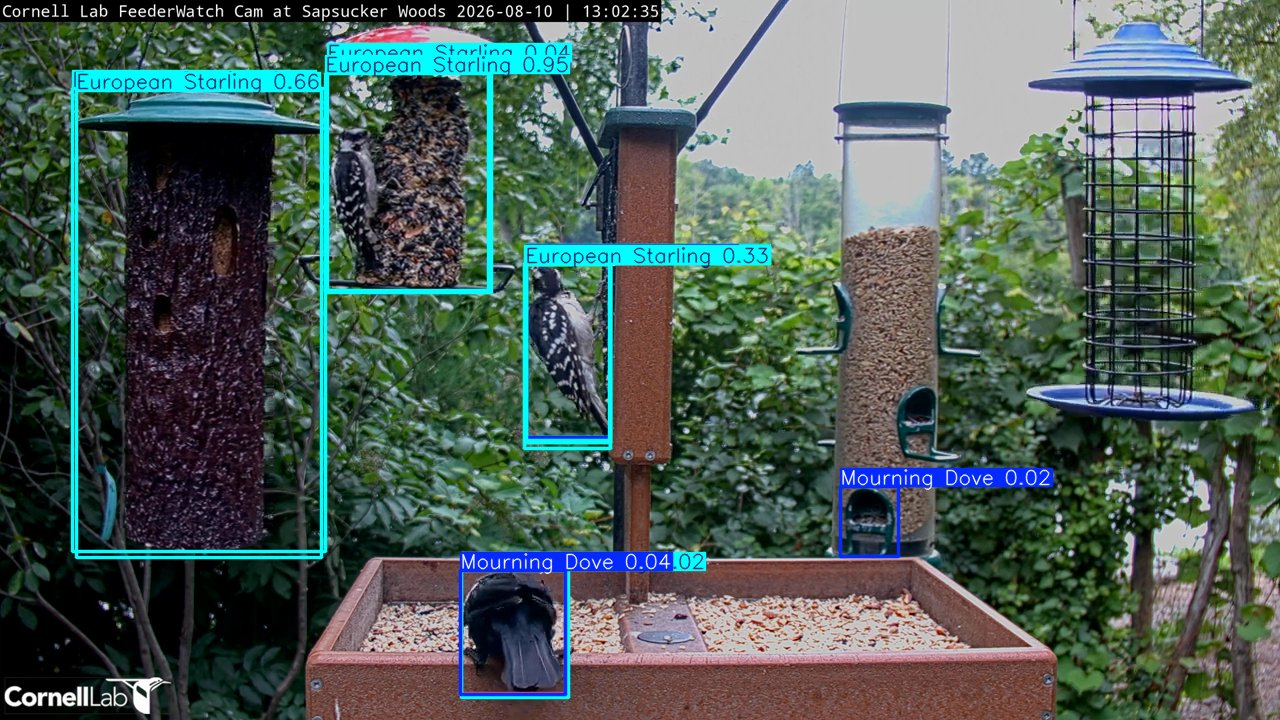

In [27]:
# ============================================================================
#  8. STREAM ACCESS + PREFLIGHT
# ============================================================================
# The preflight is the answer to "is it the streaming or the detection?".
# It opens the stream, times the first frame, runs one inference, and shows
# you the annotated result — all synchronously, in this cell, where errors are
# actually visible. Run it before committing to a long session.
# ============================================================================

import yt_dlp

# FFmpeg will otherwise block inside cap.read() indefinitely on a dead network
# stream, which makes the reader thread unstoppable. Must be set before the
# first VideoCapture is constructed. Values are microseconds.
os.environ.setdefault("OPENCV_FFMPEG_CAPTURE_OPTIONS",
                      "rw_timeout;15000000|timeout;15000000|reconnect;1|reconnect_streamed;1")

_STREAM_CACHE = {"url": None, "resolved_at": 0.0}


def resolve_stream_url(video_id=None, force=False):
    """Resolve a playable direct URL. Cached for 30 min (these links expire)."""
    if STREAM_URL_OVERRIDE:
        return STREAM_URL_OVERRIDE

    if not force and _STREAM_CACHE["url"] and time.time() - _STREAM_CACHE["resolved_at"] < 1800:
        return _STREAM_CACHE["url"]

    video_id = video_id or YOUTUBE_VIDEO_ID
    watch_url = f"https://www.youtube.com/watch?v={video_id}"
    opts = {"quiet": True, "no_warnings": True,
            "format": f"best[height<=?{STREAM_MAX_HEIGHT}]/best"}
    try:
        with yt_dlp.YoutubeDL(opts) as ydl:
            info = ydl.extract_info(watch_url, download=False)
    except Exception as exc:
        log.error(f"yt-dlp could not resolve {watch_url}: {exc}")
        return None

    url = info.get("url")
    if not url:                       # merged format — dig for a video stream
        for fmt in sorted(info.get("formats", []),
                          key=lambda f: (f.get("height") or 0), reverse=True):
            if fmt.get("vcodec") not in (None, "none") and fmt.get("url"):
                if (fmt.get("height") or 0) <= STREAM_MAX_HEIGHT:
                    url = fmt["url"]
                    break

    _STREAM_CACHE.update(url=url, resolved_at=time.time())
    log.info(f"Stream: {info.get('title')}  "
             f"({'LIVE' if info.get('is_live') else 'VOD'}, "
             f"{info.get('height') or '?'}p)")
    return url


def open_capture(url):
    cap = cv2.VideoCapture(url)
    cap.set(cv2.CAP_PROP_BUFFERSIZE, 1)     # we always want the newest frame
    # Honoured by some OpenCV backends only; harmless where it is not.
    for prop, ms in (("CAP_PROP_OPEN_TIMEOUT_MSEC", 15000),
                     ("CAP_PROP_READ_TIMEOUT_MSEC", 15000)):
        if hasattr(cv2, prop):
            cap.set(getattr(cv2, prop), ms)
    if not cap.isOpened():
        log.error("cv2.VideoCapture could not open the stream. Usually this is "
                  "an expired URL or an OpenCV build without FFmpeg/HLS support.")
        cap.release()
        return None
    return cap


def preflight(model_path=None, n_frames: int = 12):
    """Prove the stream works, prove the model works, show one annotated frame."""
    print("=" * 68)
    print("PREFLIGHT")
    print("=" * 68)

    # --- 1. stream ------------------------------------------------------
    t0 = time.time()
    url = resolve_stream_url(force=True)
    if not url:
        print("✗ STREAM: could not resolve a URL. Nothing downstream can work.")
        return None
    print(f"✓ URL resolved in {time.time() - t0:.1f}s")

    t0 = time.time()
    cap = open_capture(url)
    if cap is None:
        print("✗ STREAM: URL resolved but OpenCV refused to open it.")
        return None
    print(f"✓ Capture opened in {time.time() - t0:.1f}s")

    t0, frames, frame = time.time(), 0, None
    while frames < n_frames and time.time() - t0 < 20:
        ok, f = cap.read()
        if not ok:
            break
        frames, frame = frames + 1, f
    cap.release()

    if frame is None:
        print("✗ STREAM: opened but returned no frames in 20s.\n"
              "  THIS is the failure mode that left your database empty.")
        return None
    elapsed = time.time() - t0
    h, w = frame.shape[:2]
    print(f"✓ Read {frames} frames in {elapsed:.1f}s ({frames / max(elapsed, .01):.1f} fps), {w}x{h}")

    # --- 2. model -------------------------------------------------------
    path = Path(model_path) if model_path else MODEL_PATH
    model = YOLO(str(path))
    names = model.names
    is_stock = len(names) == 80 and names.get(14) == "bird"
    print(f"\n✓ Model loaded: {path}")
    print(f"  classes: {len(names)}  ->  {list(names.values())[:6]}"
          f"{' ...' if len(names) > 6 else ''}")
    if is_stock:
        print("  ⚠ This is the stock COCO model. It detects a generic 'bird',")
        print("    not species. Train first, or set MODEL_PATH_OVERRIDE.")

    t0 = time.time()
    result = model(frame, conf=0.01, iou=IOU_THRESHOLD, imgsz=INFER_IMGSZ, verbose=False)[0]
    print(f"  inference: {(time.time() - t0) * 1000:.0f}ms on {DEVICE}")

    confs = sorted((float(b.conf[0]) for b in result.boxes), reverse=True)
    print(f"\n  raw boxes at conf>=0.01 : {len(confs)}")
    for t in (0.1, 0.25, 0.35, 0.5, 0.7):
        print(f"  boxes at conf>={t:<5}      : {sum(c >= t for c in confs)}")
    if confs:
        top = [(names[int(b.cls[0])], float(b.conf[0])) for b in result.boxes]
        top.sort(key=lambda x: -x[1])
        print("\n  top candidates: " + ", ".join(f"{n} {c:.2f}" for n, c in top[:5]))
    else:
        print("\n  Nothing found at all — either no bird is on camera right now,")
        print("  or the model is undertrained. Try a screenshot with a known bird.")

    # --- 3. show it -----------------------------------------------------
    annotated = result.plot(conf=True, line_width=2)
    ok, buf = cv2.imencode(".jpg", annotated, [cv2.IMWRITE_JPEG_QUALITY, 85])
    if ok:
        display(IPyImage(data=buf.tobytes(), width=LIVE_DISPLAY_W))

    print("=" * 68)
    return {"url": url, "frame": frame, "model": model, "result": result}


PREFLIGHT = preflight()


In [28]:
# ============================================================================
#  8b. STREAM THE ANNOTATED OUTPUT
# ============================================================================
# The live loop already builds exactly what you would want to broadcast: the
# frame result.plot() hands back, boxes and species labels burned in. All this
# cell does is get that numpy array off the notebook and somewhere a browser
# can reach it.
#
# MJPEG vs everything else — the choice matters more than it looks:
#
#   mjpeg   A boundary-delimited stream of JPEGs over HTTP. Renders in a plain
#           <img> tag in every browser: no ffmpeg, no player library, no
#           transcode, latency of one inference interval. Bandwidth is linear
#           per viewer and there is no audio. For a 4 fps feeder cam with a
#           handful of viewers this is the right answer and the rest of the
#           cell is overkill.
#
#   hls     H.264 segments on disk plus a static server. Costs 3-6 seconds of
#           latency, buys efficient delivery to many viewers and a recording.
#   rtmp    The same encode, pushed to YouTube or Twitch.
#   rtsp    The same encode, handed to a media server that can republish it as
#           WebRTC — see the note at the bottom of the notebook for MediaMTX.
#
# One design point worth understanding, because getting it wrong is how a
# stream-out feature freezes your detector: the inference loop must never
# block on ffmpeg. If stdin backs up — slow disk, stalled upload — a naive
# write() stops detection dead. So writes land in a 1-slot buffer and a pacer
# thread feeds ffmpeg at a fixed cadence, repeating the last frame when
# inference is slower than the output rate. The side benefit is that the -r we
# declare to ffmpeg is true, which is what keeps HLS playlist timing honest.
# ============================================================================

import socket
import functools
import subprocess
import http.server
import socketserver


def in_docker() -> bool:
    if Path("/.dockerenv").exists():
        return True
    try:
        return "docker" in Path("/proc/1/cgroup").read_text()
    except OSError:
        return False


def proxy_hint(port: int) -> list:
    """
    jupyter-server-proxy tunnels an arbitrary local port through the URL
    JupyterLab is already served on — no second published port, and it
    inherits Jupyter's own auth and TLS. Worth having in a container image.
    """
    try:
        import jupyter_server_proxy  # noqa: F401
    except ImportError:
        return []
    return [f"<your JupyterLab URL>/proxy/{port}/  (via jupyter-server-proxy)"]


def container_note(port: int) -> list:
    if not in_docker():
        return []
    return [f"NOTE  this is a container address. Reachable from the Docker host,",
            f"      but not from your laptop unless the container was started",
            f"      with  -p {port}:{port}  (or --network host)."]


def lan_ip() -> str:
    """Best guess at the address another machine should use to reach here."""
    try:
        s = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)
        s.connect(("8.8.8.8", 80))          # picks a route, sends nothing
        ip = s.getsockname()[0]
        s.close()
        return ip
    except Exception:
        return "127.0.0.1"


class _LatestFrame:
    """
    1-slot frame holder. The producer never blocks and never queues: a viewer
    that falls behind gets the newest frame, not a backlog of stale ones.
    """

    def __init__(self):
        self._cv = threading.Condition()
        self._frame = None
        self._seq = 0

    def put(self, frame):
        with self._cv:
            self._frame = frame
            self._seq += 1
            self._cv.notify_all()

    def peek(self):
        with self._cv:
            return self._frame

    def wait(self, last_seq, timeout=5.0):
        """Block until a frame newer than last_seq arrives. -> (seq, frame)."""
        with self._cv:
            if self._seq == last_seq:
                self._cv.wait(timeout)
            return self._seq, self._frame


class _ThreadedHTTP(socketserver.ThreadingMixIn, http.server.HTTPServer):
    daemon_threads = True          # a hung viewer never holds the kernel open
    allow_reuse_address = True     # re-running this cell reclaims the port


# ---------------------------------------------------------------- MJPEG ------

_MJPEG_PAGE = """<!doctype html><meta charset=utf-8>
<title>bird detections</title>
<style>
 body{margin:0;background:#111;color:#ddd;
      font:13px ui-monospace,SFMono-Regular,Menlo,monospace}
 header{padding:8px 12px;opacity:.7}
 img{display:block;width:100%;max-width:1280px;margin:0 auto}
</style>
<header>live detections &middot; <a style="color:#6cf" href="snapshot.jpg">snapshot</a></header>
<img src="stream.mjpg" alt="waiting for the first frame">
"""


class _MJPEGHandler(http.server.BaseHTTPRequestHandler):
    protocol_version = "HTTP/1.0"
    sink = None                    # bound per-sink in MJPEGSink.__init__

    def log_message(self, fmt, *args):
        pass                       # keep the notebook output readable

    def _send(self, code, body: bytes, ctype="text/html; charset=utf-8"):
        self.send_response(code)
        self.send_header("Content-Type", ctype)
        self.send_header("Content-Length", str(len(body)))
        self.send_header("Access-Control-Allow-Origin", "*")
        self.end_headers()
        self.wfile.write(body)

    def do_GET(self):
        path = self.path.split("?")[0].rstrip("/") or "/"
        if path in ("/", "/index.html"):
            return self._send(200, _MJPEG_PAGE.encode())
        if path == "/snapshot.jpg":
            frame = self.sink.latest.peek()
            if frame is None:
                return self._send(503, b"no frame yet", "text/plain")
            ok, buf = cv2.imencode(".jpg", frame,
                                   [cv2.IMWRITE_JPEG_QUALITY, self.sink.quality])
            return self._send(200, buf.tobytes(), "image/jpeg")
        if path == "/stream.mjpg":
            return self._stream()
        return self._send(404, b"not found", "text/plain")

    def _stream(self):
        self.send_response(200)
        self.send_header("Age", "0")
        self.send_header("Cache-Control", "no-store, no-cache, must-revalidate")
        self.send_header("Pragma", "no-cache")
        self.send_header("Content-Type", "multipart/x-mixed-replace; boundary=frame")
        self.end_headers()
        self.sink.viewer_joined()
        seq = -1
        try:
            while True:
                seq, frame = self.sink.latest.wait(seq, timeout=5.0)
                if frame is None:
                    continue
                ok, buf = cv2.imencode(".jpg", frame,
                                       [cv2.IMWRITE_JPEG_QUALITY, self.sink.quality])
                if not ok:
                    continue
                blob = buf.tobytes()
                self.wfile.write(b"--frame\r\nContent-Type: image/jpeg\r\n"
                                 b"Content-Length: " + str(len(blob)).encode()
                                 + b"\r\n\r\n")
                self.wfile.write(blob)
                self.wfile.write(b"\r\n")
                self.sink.sent += 1
        except (BrokenPipeError, ConnectionResetError, OSError):
            pass                   # tab closed; not worth a log line
        finally:
            self.sink.viewer_left()


class MJPEGSink:
    """JPEG-over-HTTP. No ffmpeg, no encode settings, no latency stack."""

    label = "mjpeg"

    def __init__(self, port=None, quality=None, bind=None):
        self.port = int(port or MJPEG_PORT)
        self.quality = int(quality or MJPEG_QUALITY)
        self.bind = bind or MJPEG_BIND
        self.latest = _LatestFrame()
        self.viewers = 0
        self.sent = 0
        self.error = None
        self._vlock = threading.Lock()
        handler = type("_BoundMJPEGHandler", (_MJPEGHandler,), {"sink": self})
        self.server = _ThreadedHTTP((self.bind, self.port), handler)
        self.thread = threading.Thread(target=self.server.serve_forever,
                                       daemon=True, name="mjpeg")

    def viewer_joined(self):
        with self._vlock:
            self.viewers += 1

    def viewer_left(self):
        with self._vlock:
            self.viewers = max(0, self.viewers - 1)

    def start(self):
        self.thread.start()
        return self

    def write(self, frame):
        self.latest.put(frame)

    def stop(self):
        try:
            self.server.shutdown()
            self.server.server_close()
        except Exception:
            pass
        if self.thread.is_alive():
            self.thread.join(timeout=5)
        return self

    def urls(self):
        host = "127.0.0.1" if self.bind == "127.0.0.1" else lan_ip()
        return ([f"http://{host}:{self.port}/            (page)",
                 f"http://{host}:{self.port}/stream.mjpg (raw, drop in an <img>)"]
                + proxy_hint(self.port) + container_note(self.port))

    def stats_html(self):
        return (f"mjpeg :{self.port} &middot; <b>{self.viewers}</b> viewer(s)"
                f" &middot; {self.sent} frames sent")


# --------------------------------------------------------------- ffmpeg ------

def _h264_args(gop_seconds=2.0):
    """Encoder settings, adapted to whichever encoder was asked for."""
    gop = ["-g", str(max(2, round(STREAM_OUT_FPS * gop_seconds)))]
    if FFMPEG_ENCODER == "libx264":
        return ["-c:v", "libx264", "-preset", FFMPEG_PRESET, "-tune", "zerolatency",
                "-crf", str(FFMPEG_CRF), "-pix_fmt", "yuv420p"] + gop
    if "nvenc" in FFMPEG_ENCODER:
        return ["-c:v", FFMPEG_ENCODER, "-preset", "p4", "-tune", "ll",
                "-rc", "vbr", "-cq", str(FFMPEG_CRF), "-pix_fmt", "yuv420p"] + gop
    return ["-c:v", FFMPEG_ENCODER, "-pix_fmt", "yuv420p"] + gop


class FFmpegSink:
    """
    Raw BGR into ffmpeg's stdin; the output args decide where it comes out.

    Geometry is fixed at launch, which matters here: STREAM_RECONNECT can bring
    the YouTube stream back at a different resolution, and feeding ffmpeg a
    frame of the wrong size produces tearing garbage rather than an error. Any
    mismatched frame is conformed to the size ffmpeg was told about.
    """

    def __init__(self, label, output_args, fps=None, log_path=None):
        self.label = label
        self.output_args = [str(a) for a in output_args]
        self.fps = float(fps or STREAM_OUT_FPS)
        self.log_path = Path(log_path or (ROOT / f"ffmpeg_{label}.log"))
        self.latest = _LatestFrame()
        self.size = None
        self.proc = None
        self.log_fh = None
        self.running = False
        self.thread = None
        self.written = 0
        self.conformed = 0
        self.error = None
        self._lock = threading.Lock()

    def start(self):
        if shutil.which(FFMPEG_BIN) is None:
            raise RuntimeError(
                f"{FFMPEG_BIN!r} is not on PATH. Install ffmpeg, or drop the "
                f"ffmpeg-backed modes from STREAM_OUT and use 'mjpeg'.")
        self.running = True
        self.thread = threading.Thread(target=self._pump, daemon=True,
                                       name=f"ffmpeg-{self.label}")
        self.thread.start()
        return self

    def _spawn(self, w, h):
        self.log_fh = open(self.log_path, "wb")
        cmd = ([FFMPEG_BIN, "-hide_banner", "-loglevel", "warning",
                "-f", "rawvideo", "-pix_fmt", "bgr24", "-s", f"{w}x{h}",
                "-r", f"{self.fps:g}", "-i", "pipe:0", "-an"]
               + self.output_args)
        log.info(f"[{self.label}] {' '.join(cmd)}")
        # stderr goes to the log file rather than a pipe on purpose: an
        # undrained stderr pipe fills, and then ffmpeg blocks forever.
        self.proc = subprocess.Popen(cmd, stdin=subprocess.PIPE,
                                     stdout=self.log_fh, stderr=self.log_fh,
                                     bufsize=0)
        self.size = (w, h)

    def write(self, frame):
        h, w = frame.shape[:2]
        with self._lock:
            if self.size is None:
                self._spawn(w, h)
            elif (w, h) != self.size:
                frame = cv2.resize(frame, self.size, interpolation=cv2.INTER_AREA)
                self.conformed += 1
        self.latest.put(frame)

    def _pump(self):
        interval = 1.0 / self.fps
        next_t = time.time()
        while self.running:
            now = time.time()
            if now < next_t:
                time.sleep(min(next_t - now, 0.02))
                continue
            next_t = max(now, next_t + interval)   # never accumulate debt
            proc, frame = self.proc, self.latest.peek()
            if proc is None or frame is None:
                continue
            if proc.poll() is not None:
                self.error = f"ffmpeg exited {proc.returncode} — see {self.log_path.name}"
                log.error(f"[{self.label}] {self.error}\n{self.tail()}")
                break
            try:
                proc.stdin.write(np.ascontiguousarray(frame).tobytes())
                self.written += 1
            except (BrokenPipeError, ValueError, OSError) as exc:
                self.error = f"pipe closed: {exc}"
                break
        self.running = False

    def stop(self):
        self.running = False
        if self.thread and self.thread.is_alive():
            self.thread.join(timeout=5)
        proc = self.proc
        if proc is not None:
            try:
                if proc.stdin and not proc.stdin.closed:
                    proc.stdin.close()     # EOF is what makes ffmpeg finalise
            except Exception:              # the playlist / flush the muxer
                pass
            try:
                proc.wait(timeout=10)
            except subprocess.TimeoutExpired:
                proc.terminate()
                try:
                    proc.wait(timeout=5)
                except subprocess.TimeoutExpired:
                    proc.kill()
        if self.log_fh:
            try:
                self.log_fh.close()
            except Exception:
                pass
        return self

    def tail(self, n=12):
        """ffmpeg's own account of what went wrong. Read this first."""
        if not self.log_path.exists():
            return "(no ffmpeg log yet)"
        return "\n".join(self.log_path.read_text(errors="replace").splitlines()[-n:])

    def urls(self):
        return [f"pushing to: {self.output_args[-1]}"]

    def stats_html(self):
        state = f"<span style='color:#c00'>{self.error}</span>" if self.error else "ok"
        conf = f" &middot; {self.conformed} resized" if self.conformed else ""
        return f"{self.label} &middot; {self.written} frames &middot; {state}{conf}"


# ------------------------------------------------------------------ HLS ------

_HLS_PAGE = """<!doctype html><meta charset=utf-8>
<title>bird detections (HLS)</title>
<style>body{margin:0;background:#111}video{display:block;width:100%;max-width:1280px;margin:0 auto}</style>
<video id="v" controls autoplay muted playsinline></video>
<script src="https://cdn.jsdelivr.net/npm/hls.js@1/dist/hls.min.js"></script>
<script>
const v = document.getElementById('v'), src = 'index.m3u8';
if (v.canPlayType('application/vnd.apple.mpegurl')) {      // Safari / iOS
  v.src = src;
} else if (window.Hls && Hls.isSupported()) {
  const h = new Hls({lowLatencyMode: true, liveSyncDurationCount: 2});
  h.loadSource(src); h.attachMedia(v);
} else {
  document.body.innerHTML = '<p style="color:#ddd;font-family:monospace;padding:1em">' +
    'This browser needs hls.js and the CDN did not load.</p>';
}
</script>
"""


class _StaticHandler(http.server.SimpleHTTPRequestHandler):
    extensions_map = {**http.server.SimpleHTTPRequestHandler.extensions_map,
                      ".m3u8": "application/vnd.apple.mpegurl",
                      ".ts": "video/mp2t"}

    def log_message(self, fmt, *args):
        pass

    def end_headers(self):
        self.send_header("Access-Control-Allow-Origin", "*")
        self.send_header("Cache-Control", "no-store")
        super().end_headers()


class HLSSink:
    """ffmpeg segments to a directory; a small static server hands it out."""

    label = "hls"

    def __init__(self, directory=None, port=None):
        self.dir = Path(directory or HLS_DIR or (ROOT / "stream"))
        self.port = int(port or HLS_PORT)
        self.ff = None
        self.server = None
        self.thread = None
        self.error = None

    def start(self):
        # Wipe old segments: a stale playlist is worse than none, because the
        # player loads yesterday's birds and looks like it is working.
        shutil.rmtree(self.dir, ignore_errors=True)
        self.dir.mkdir(parents=True, exist_ok=True)
        (self.dir / "index.html").write_text(_HLS_PAGE)

        args = _h264_args(HLS_SEGMENT_SECONDS) + [
            "-f", "hls",
            "-hls_time", str(HLS_SEGMENT_SECONDS),
            "-hls_list_size", str(HLS_WINDOW),
            # temp_file stops the static server ever handing out a half-written
            # segment; delete_segments keeps the directory from growing forever.
            "-hls_flags", "delete_segments+independent_segments+temp_file",
            "-hls_segment_type", "mpegts",
            "-hls_segment_filename", str(self.dir / "seg_%05d.ts"),
            str(self.dir / "index.m3u8"),
        ]
        self.ff = FFmpegSink("hls", args).start()

        handler = functools.partial(_StaticHandler, directory=str(self.dir))
        self.server = _ThreadedHTTP((MJPEG_BIND, self.port), handler)
        self.thread = threading.Thread(target=self.server.serve_forever,
                                       daemon=True, name="hls-http")
        self.thread.start()
        return self

    def write(self, frame):
        self.ff.write(frame)

    def stop(self):
        if self.ff:
            self.ff.stop()
        try:
            self.server.shutdown()
            self.server.server_close()
        except Exception:
            pass
        if self.thread and self.thread.is_alive():
            self.thread.join(timeout=5)
        return self

    def urls(self):
        host = "127.0.0.1" if MJPEG_BIND == "127.0.0.1" else lan_ip()
        return ([f"http://{host}:{self.port}/             (player)",
                 f"http://{host}:{self.port}/index.m3u8  (playlist)"]
                + proxy_hint(self.port) + container_note(self.port))

    def tail(self, n=12):
        return self.ff.tail(n) if self.ff else "(not started)"

    def stats_html(self):
        return self.ff.stats_html() if self.ff else "hls &middot; not started"


# ------------------------------------------------------------- fan-out -------

class SinkGroup:
    """Whatever combination of outputs survived setup, driven as one thing."""

    def __init__(self, sinks):
        self.sinks = list(sinks)

    def __bool__(self):
        return bool(self.sinks)

    def write(self, frame):
        for sink in self.sinks:
            try:
                sink.write(frame)
            except Exception as exc:
                if sink.error is None:          # log the first failure only
                    sink.error = str(exc)
                    log.error(f"[{sink.label}] write failed: {exc}")

    def stop(self):
        for sink in self.sinks:
            try:
                sink.stop()
            except Exception as exc:
                log.warning(f"[{sink.label}] stop: {exc}")
        return self

    def announce(self):
        for sink in self.sinks:
            for line in sink.urls():
                print(f"  {sink.label:<6} {line}", flush=True)
        if self.sinks:
            print(flush=True)

    def stats_html(self):
        if not self.sinks:
            return ""
        rows = "<br>".join(s.stats_html() for s in self.sinks)
        return ("<div><div style='font-weight:600;margin-bottom:4px'>Streaming out"
                f"</div>{rows}</div>")


def make_sinks(modes=None) -> SinkGroup:
    """
    Build the requested outputs. A sink that cannot start is logged and left
    out rather than killing the run — losing the broadcast is annoying, losing
    the detection session because the broadcast failed is worse.
    """
    wanted = [str(m).strip().lower() for m in (STREAM_OUT if modes is None else modes)]
    sinks = []
    for mode in wanted:
        if mode in ("", "off", "none"):
            continue
        try:
            if mode == "mjpeg":
                sinks.append(MJPEGSink().start())
            elif mode == "hls":
                sinks.append(HLSSink().start())
            elif mode == "rtmp":
                if not RTMP_URL:
                    raise RuntimeError("RTMP_URL is not set in the Control Panel")
                sinks.append(FFmpegSink(
                    "rtmp", _h264_args(2.0) + ["-f", "flv", RTMP_URL]).start())
            elif mode == "rtsp":
                if not RTSP_URL:
                    raise RuntimeError("RTSP_URL is not set in the Control Panel")
                sinks.append(FFmpegSink(
                    "rtsp", _h264_args(1.0)
                    + ["-f", "rtsp", "-rtsp_transport", "tcp", RTSP_URL]).start())
            else:
                raise RuntimeError(f"unknown STREAM_OUT mode {mode!r}")
        except OSError as exc:
            log.error(f"stream-out '{mode}' disabled — {exc} "
                      f"(port already in use? a previous run may still hold it)")
        except Exception as exc:
            log.error(f"stream-out '{mode}' disabled — {exc}")
    return SinkGroup(sinks)


print("Stream-out ready.")
print(f"  requested : {', '.join(STREAM_OUT) or 'off'}")
print(f"  ffmpeg    : {shutil.which(FFMPEG_BIN) or 'NOT FOUND (mjpeg still works)'}")
print(f"  container : {'yes — see the URL notes when a session starts' if in_docker() else 'no'}")
print(f"  proxy ext : {'jupyter-server-proxy present' if proxy_hint(0) else 'not installed'}")


Stream-out ready.
  requested : mjpeg
  ffmpeg    : /usr/bin/ffmpeg
  container : yes — see the URL notes when a session starts
  proxy ext : not installed


In [29]:
# ============================================================================
#  9. LIVE DETECTION
# ============================================================================
# Architecture:
#
#   reader thread  ->  1-slot buffer  ->  MAIN THREAD (inference, DB, display)
#
# The capture read has to be threaded or OpenCV hands you a backlog of stale
# frames. Everything else runs on the main thread so exceptions land in this
# cell's output instead of vanishing into a daemon.
#
# THREE WAYS TO STOP, in order of reliability:
#
#   1. touch bird_project/STOP     from a terminal — always works
#   2. interrupt the kernel (■)    clean, prints the summary
#   3. wait for LIVE_MAX_MINUTES   automatic
#
# Option 1 exists because Jupyter cannot run a second cell while this one is
# blocking, so a "stop button" widget can never fire — its callback needs the
# kernel's event loop, which this loop is holding. A file on disk can.
# ============================================================================

STOP_FILE = ROOT / "STOP"

# Survives re-running this cell, so an interrupted session can still be reaped.
_ACTIVE = globals().get("_ACTIVE",
                        {"grabber": None, "db": None, "stop": None, "sinks": None})


def _uninterruptible(fn, *args, **kwargs):
    """
    Run cleanup even if the interrupt button gets hammered.

    A second SIGINT landing during teardown is the usual reason a session
    half-stops: threads survive, nothing prints, and the next run stacks
    another reader thread on top of the last one.
    """
    for _ in range(8):
        try:
            return fn(*args, **kwargs)
        except KeyboardInterrupt:
            continue


def stop_live(quiet=False):
    """Signal the running session to stop, and reap anything orphaned."""
    event, grabber, db = _ACTIVE.get("stop"), _ACTIVE.get("grabber"), _ACTIVE.get("db")
    sinks = _ACTIVE.get("sinks")
    if event is not None:
        event.set()
    if grabber is not None:
        _uninterruptible(grabber.stop)
    if db is not None:
        _uninterruptible(db.stop)
    if sinks is not None:
        # Sockets and ffmpeg processes outlive an interrupted cell. Reaping
        # them here is what lets you re-run without "address already in use".
        _uninterruptible(sinks.stop)
    _ACTIVE.update(grabber=None, db=None, stop=None, sinks=None)
    STOP_FILE.unlink(missing_ok=True)
    if not quiet and (grabber is not None or db is not None or sinks is not None):
        print("Reaped a session left over from a previous run.", flush=True)


class FrameGrabber:
    """Continuously reads the newest frame, reconnecting when the URL expires."""

    def __init__(self, url_factory):
        self.url_factory = url_factory
        self.lock = threading.Lock()
        self._frame = None
        self._seq = 0
        self.running = False
        self.thread = None
        self.reconnects = 0
        self.error = None

    def start(self):
        self.running = True
        self.thread = threading.Thread(target=self._loop, daemon=True, name="grabber")
        self.thread.start()
        return self

    def stop(self):
        self.running = False
        if self.thread:
            self.thread.join(timeout=8)
            if self.thread.is_alive():
                log.warning("Reader thread still blocked inside cap.read(). It is a "
                            "daemon and will exit on its own; saying so rather than "
                            "pretending the stop was clean.")
        return self

    def read(self):
        with self.lock:
            if self._frame is None:
                return 0, None
            return self._seq, self._frame.copy()

    def _loop(self):
        force = False
        while self.running:
            try:
                url = self.url_factory(force=force)
                if not url:
                    self.error = "could not resolve stream URL"
                    time.sleep(5)
                    force = True
                    continue
                cap = open_capture(url)
                if cap is None:
                    self.error = "could not open capture"
                    time.sleep(5)
                    force = True
                    continue

                self.error = None
                stalls = 0
                while self.running:
                    ok, frame = cap.read()
                    if not ok:
                        stalls += 1
                        if stalls > STREAM_STALL_LIMIT:
                            break
                        time.sleep(0.05)
                        continue
                    stalls = 0
                    with self.lock:
                        self._frame = frame
                        self._seq += 1
                cap.release()

                if not (self.running and STREAM_RECONNECT):
                    break
                self.reconnects += 1
                force = True
                log.info(f"Stream stalled — reconnecting (#{self.reconnects})")
            except Exception as exc:
                self.error = str(exc)
                time.sleep(3)
                force = True


def _use_widgets() -> bool:
    """
    Decide how to draw, per LIVE_VIEW.

    "ipywidgets imports in the kernel" and "the frontend can render a widget"
    are two different facts, and the failure mode of the second is a printed
    repr rather than an exception — which is why this is a setting and not a
    try/except. "auto" checks for the frontend packages, which catches the
    common case of ipywidgets installed on its own.
    """
    if not HAVE_WIDGETS or LIVE_VIEW == "still":
        return False
    if LIVE_VIEW == "widget":
        return True
    try:
        major = int(str(widgets.__version__).split(".")[0])
        if major >= 8:
            import jupyterlab_widgets  # noqa: F401
        else:
            import widgetsnbextension  # noqa: F401
        return True
    except Exception:
        return False


class LiveView:
    """Inline video + stats. Widget when asked for and supported, stills otherwise."""

    def __init__(self, width=None):
        self.width = width or LIVE_DISPLAY_W
        self.use_widgets = _use_widgets()
        if not self.use_widgets and LIVE_VIEW != "still":
            print("Live view : still frames — no ipywidgets frontend detected. "
                  "LIVE_VIEW = 'widget' forces it.", flush=True)
        if self.use_widgets:
            self.image = widgets.Image(format="jpeg", width=self.width)
            self.stats = widgets.HTML()
            display(widgets.VBox([self.image, self.stats]))
        else:
            self._img_handle = display(HTML("<i>waiting for first frame…</i>"),
                                       display_id="birdcam_img")
            self._txt_handle = display(HTML(""), display_id="birdcam_txt")

    def update(self, frame, stats_html):
        ok, buf = cv2.imencode(".jpg", frame,
                               [cv2.IMWRITE_JPEG_QUALITY, LIVE_JPEG_QUALITY])
        if not ok:
            return
        if self.use_widgets:
            self.image.value = buf.tobytes()
            self.stats.value = stats_html
        else:
            self._img_handle.update(IPyImage(data=buf.tobytes(), width=self.width))
            self._txt_handle.update(HTML(stats_html))

    def finish(self, html):
        """Mirror the summary into the widget — stdout can be lost on interrupt."""
        try:
            if self.use_widgets:
                self.stats.value = html
            else:
                self._txt_handle.update(HTML(html))
        except Exception:
            pass


def _stats_html(elapsed, frames, inferences, db, tally, recent, grabber):
    rows = "".join(
        f"<tr><td style='padding:1px 10px 1px 0'>{s}</td>"
        f"<td style='padding:1px 10px 1px 0;text-align:right'><b>{n}</b></td></tr>"
        for s, n in sorted(tally.items(), key=lambda kv: -kv[1])[:8]
    ) or "<tr><td colspan=2><i>nothing yet</i></td></tr>"

    last = "<br>".join(
        f"<span style='opacity:.75'>{t}</span> &nbsp;{s} <b>{c:.2f}</b>"
        for t, s, c in list(recent)[-6:][::-1]
    ) or "<i>no detections yet</i>"

    _sinks = _ACTIVE.get("sinks")
    sinks_block = _sinks.stats_html() if _sinks else ""

    status = (f"<span style='color:#c00'>⚠ {grabber.error}</span>"
              if grabber.error else "<span style='color:#0a0'>● live</span>")
    reconnects = f" · {grabber.reconnects} reconnect(s)" if grabber.reconnects else ""

    return f"""
    <div style="font-family:ui-monospace,SFMono-Regular,Menlo,monospace;font-size:12px;
                display:flex;gap:28px;padding:8px 2px;flex-wrap:wrap">
      <div>
        <div style="font-weight:600;margin-bottom:4px">Session</div>
        {status}{reconnects}<br>
        elapsed &nbsp;<b>{elapsed:5.0f}s</b> / {LIVE_MAX_MINUTES * 60}s<br>
        frames &nbsp;&nbsp;<b>{frames}</b><br>
        inferences <b>{inferences}</b> ({inferences / max(elapsed, 1):.1f}/s)
      </div>
      <div>
        <div style="font-weight:600;margin-bottom:4px">Logged</div>
        saved &nbsp;&nbsp;<b>{db.written if db else 0}</b><br>
        throttled <b>{db.dropped if db else 0}</b><br>
        queue &nbsp;&nbsp;<b>{db.queue.qsize() if db else 0}</b>
      </div>
      <div>
        <div style="font-weight:600;margin-bottom:4px">Seen this session</div>
        <table style="border-collapse:collapse">{rows}</table>
      </div>
      <div>
        <div style="font-weight:600;margin-bottom:4px">Latest</div>
        {last}
      </div>
      {sinks_block}
    </div>"""


def prune_captures(limit=None):
    limit = limit or FRAME_MAX_FILES
    files = sorted(CAPTURE_DIR.glob("*.jpg"), key=lambda p: p.stat().st_mtime)
    for old in files[:max(0, len(files) - limit)]:
        old.unlink(missing_ok=True)


def _shutdown_live(db, grabber, view, sinks, start, frames, inferences, tally, reason):
    if grabber is not None:
        grabber.stop()
    if db is not None:
        db.stop()
    if sinks is not None:
        sinks.stop()
    _ACTIVE.update(grabber=None, db=None, stop=None, sinks=None)
    STOP_FILE.unlink(missing_ok=True)

    elapsed = time.time() - start
    lines = [
        f"Session ended — {reason}",
        f"  elapsed        : {elapsed:.0f}s",
        f"  frames shown   : {frames}",
        f"  inferences     : {inferences} ({inferences / max(elapsed, 1):.2f}/s)",
        f"  rows written   : {db.written if db else 0}",
        f"  rows throttled : {db.dropped if db else 0}",
        f"  reconnects     : {grabber.reconnects if grabber else 0}",
        f"  species seen   : {', '.join(sorted(tally)) or 'none'}",
        f"  captures       : {len(list(CAPTURE_DIR.glob('*.jpg')))} in {CAPTURE_DIR}",
    ]
    for sink in (sinks.sinks if sinks else []):
        detail = f"pushed {getattr(sink, 'written', getattr(sink, 'sent', 0))} frames"
        if getattr(sink, "error", None):
            detail += f" — {sink.error}"
        lines.append(f"  stream {sink.label:<8}: {detail}")
    if db is not None and db.written == 0:
        lines += ["", "  No rows written. Check, in order:",
                  "   • did the video actually move?   -> stream problem",
                  "   • any boxes drawn at all?        -> lower CONF_THRESHOLD",
                  "   • boxes but nothing logged?      -> lower DB_MIN_CONFIDENCE"]

    print("\n" + "=" * 60, flush=True)
    for line in lines:
        print(line, flush=True)
    print("=" * 60, flush=True)
    sys.stdout.flush()

    # stdout can be dropped when a cell is interrupted mid-flush; the widget is
    # a separate channel to the browser, so put the summary there as well.
    if view is not None:
        view.finish(
            "<div style='font-family:ui-monospace,Menlo,monospace;font-size:12px;"
            "white-space:pre;padding:8px;border-left:3px solid #888'>"
            + "<br>".join(lines) + "</div>")


def run_live(minutes=None, refresh_fps=None, conf=None):
    minutes = minutes if minutes is not None else LIVE_MAX_MINUTES
    refresh_fps = refresh_fps or LIVE_REFRESH_FPS
    conf = conf if conf is not None else CONF_THRESHOLD
    interval = 1.0 / max(refresh_fps, 0.1)

    stop_live(quiet=False)                 # reap anything left over from a prior run
    STOP_FILE.unlink(missing_ok=True)

    stop_event = threading.Event()
    _ACTIVE["stop"] = stop_event

    db = grabber = view = sinks = None
    tally, recent = defaultdict(int), deque(maxlen=12)
    start = time.time()
    frames = inferences = 0
    reason = "reached the time limit"

    try:
        model = YOLO(str(MODEL_PATH))
        names = model.names
        bird_ids = [i for i, n in names.items() if str(n).lower() == "bird"]
        is_stock = len(names) == 80 and bool(bird_ids)
        class_filter = bird_ids if is_stock else None

        print(f"Model      : {MODEL_PATH.name}  ({MODEL_SOURCE})", flush=True)
        print(f"Classes    : {len(names)}"
              + ("  [filtered to COCO 'bird']" if is_stock else ""), flush=True)
        print(f"Refresh    : {refresh_fps} fps · conf {conf} · up to {minutes} min", flush=True)
        print(f"Logging    : {'on' if DB_ENABLED else 'OFF'} · frames "
              f"{'on' if SAVE_FRAMES else 'off'}", flush=True)
        print(f"Stop early : interrupt the kernel, or  touch {STOP_FILE}\n", flush=True)

        if DB_ENABLED:
            db = DetectionDB(DB_PATH, DB_COOLDOWN_SECONDS, DB_MIN_CONFIDENCE).start()
            _ACTIVE["db"] = db
        grabber = FrameGrabber(resolve_stream_url).start()
        _ACTIVE["grabber"] = grabber

        sinks = make_sinks()
        _ACTIVE["sinks"] = sinks
        if sinks:
            print("Streaming the annotated frames to:", flush=True)
            sinks.announce()

        view = LiveView()

        deadline = start + minutes * 60
        last_seq = -1
        last_frame_save = 0.0
        next_tick = time.time()

        while time.time() < deadline:
            if stop_event.is_set():
                reason = "stopped via stop_live()"
                break
            if STOP_FILE.exists():
                reason = f"stopped by {STOP_FILE}"
                break

            now = time.time()
            if now < next_tick:
                time.sleep(min(next_tick - now, 0.05))
                continue
            next_tick = now + interval

            seq, frame = grabber.read()
            if frame is None:
                view.update(np.zeros((360, 640, 3), np.uint8),
                            _stats_html(now - start, frames, inferences, db,
                                        tally, recent, grabber))
                continue
            if seq == last_seq and not LIVE_SHOW_EMPTY:
                continue
            last_seq = seq
            frames += 1

            result = model(frame, conf=conf, iou=IOU_THRESHOLD,
                           imgsz=INFER_IMGSZ, classes=class_filter, verbose=False)[0]
            inferences += 1

            hits = []
            for box in result.boxes:
                cls_id = int(box.cls[0])
                x1, y1, x2, y2 = (int(v) for v in box.xyxy[0].tolist())
                hits.append({
                    "ts": now,
                    "iso_time": datetime.fromtimestamp(now).isoformat(timespec="seconds"),
                    "species": names.get(cls_id, str(cls_id)),
                    "class_id": cls_id, "confidence": float(box.conf[0]),
                    "x1": x1, "y1": y1, "x2": x2, "y2": y2,
                    "cx": (x1 + x2) / 2, "cy": (y1 + y2) / 2,
                    "width": x2 - x1, "height": y2 - y1, "frame_path": None,
                })

            annotated = result.plot(conf=True, line_width=2)

            # Hand the broadcast the same pixels the notebook is showing.
            # This never blocks: each sink drops it into a 1-slot buffer and
            # its own thread deals with encoding and the network.
            if sinks:
                sinks.write(annotated)

            saved_path = None
            if hits and SAVE_FRAMES and now - last_frame_save >= FRAME_COOLDOWN_SECONDS:
                stamp = datetime.fromtimestamp(now).strftime("%Y%m%d_%H%M%S")
                top = max(hits, key=lambda d: d["confidence"])["species"]
                saved_path = CAPTURE_DIR / f"{stamp}_{slugify(top)}.jpg"
                cv2.imwrite(str(saved_path), annotated)
                last_frame_save = now
                prune_captures()

            for hit in hits:
                hit["frame_path"] = str(saved_path) if saved_path else None
                if db and db.offer(hit):
                    tally[hit["species"]] += 1
                    recent.append((hit["iso_time"][11:], hit["species"], hit["confidence"]))

            view.update(annotated, _stats_html(now - start, frames, inferences, db,
                                               tally, recent, grabber))

    except KeyboardInterrupt:
        reason = "interrupted from the kernel"

    finally:
        # Deliberately no `return` in here. A return inside finally swallows
        # whatever exception was propagating — which is exactly how a crashed
        # session ends up looking like a silent one, with no traceback at all.
        _uninterruptible(_shutdown_live, db, grabber, view, sinks, start,
                         frames, inferences, tally, reason)

    return db


RUN  ▶  live      a live session is never cached
Model      : best.pt  (trained species model)
Classes    : 30
Refresh    : 4.0 fps · conf 0.35 · up to 5 min
Logging    : on · frames on
Stop early : interrupt the kernel, or  touch /home/jovyan/bird_project/STOP

Streaming the annotated frames to:
  mjpeg  http://172.17.0.5:8089/            (page)
  mjpeg  http://172.17.0.5:8089/stream.mjpg (raw, drop in an <img>)
  mjpeg  NOTE  this is a container address. Reachable from the Docker host,
  mjpeg        but not from your laptop unless the container was started
  mjpeg        with  -p 8089:8089  (or --network host).



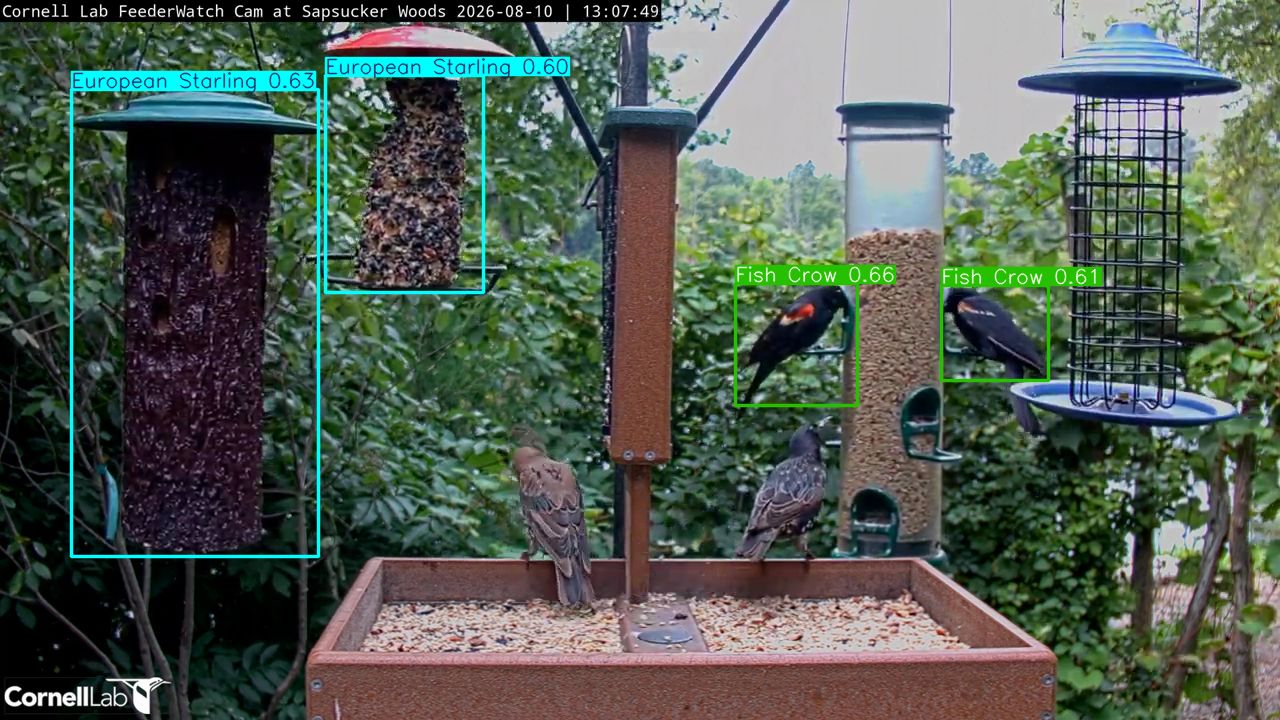


Session ended — reached the time limit
  elapsed        : 301s
  frames shown   : 1170
  inferences     : 1170 (3.89/s)
  rows written   : 97
  rows throttled : 2191
  reconnects     : 0
  species seen   : Black Vulture, Blue Jay, European Starling, Fish Crow, Great Black-backed Gull, Mourning Dove, Red-breasted Nuthatch, Song Sparrow
  captures       : 45 in /home/jovyan/bird_project/captures
  stream mjpeg   : pushed 0 frames


In [30]:
# ============================================================================
#  10. ▶ RUN
# ============================================================================
# Re-run this cell as often as you like. To change how it behaves, edit the
# Control Panel and re-run that cell first — or override just for this run:
#
#     DB = run_live(minutes=1, refresh_fps=8, conf=0.25)
# ============================================================================

RUN_LIVE = gate("live", (False, "a live session is never cached"))

if RUN_LIVE:
    DB = run_live()
else:
    DB = DetectionDB(DB_PATH)
    print("RUN_LIVE is off — connected to the existing database for analysis only.")
    DB.summary()


  detections     : 174
  species        : 12
  span           : 1087.0 min (2026-07-29 19:05 → 13:11)
  rate           : 0.2 logged/min
  confidence     : mean 0.643  median 0.629  max 0.998


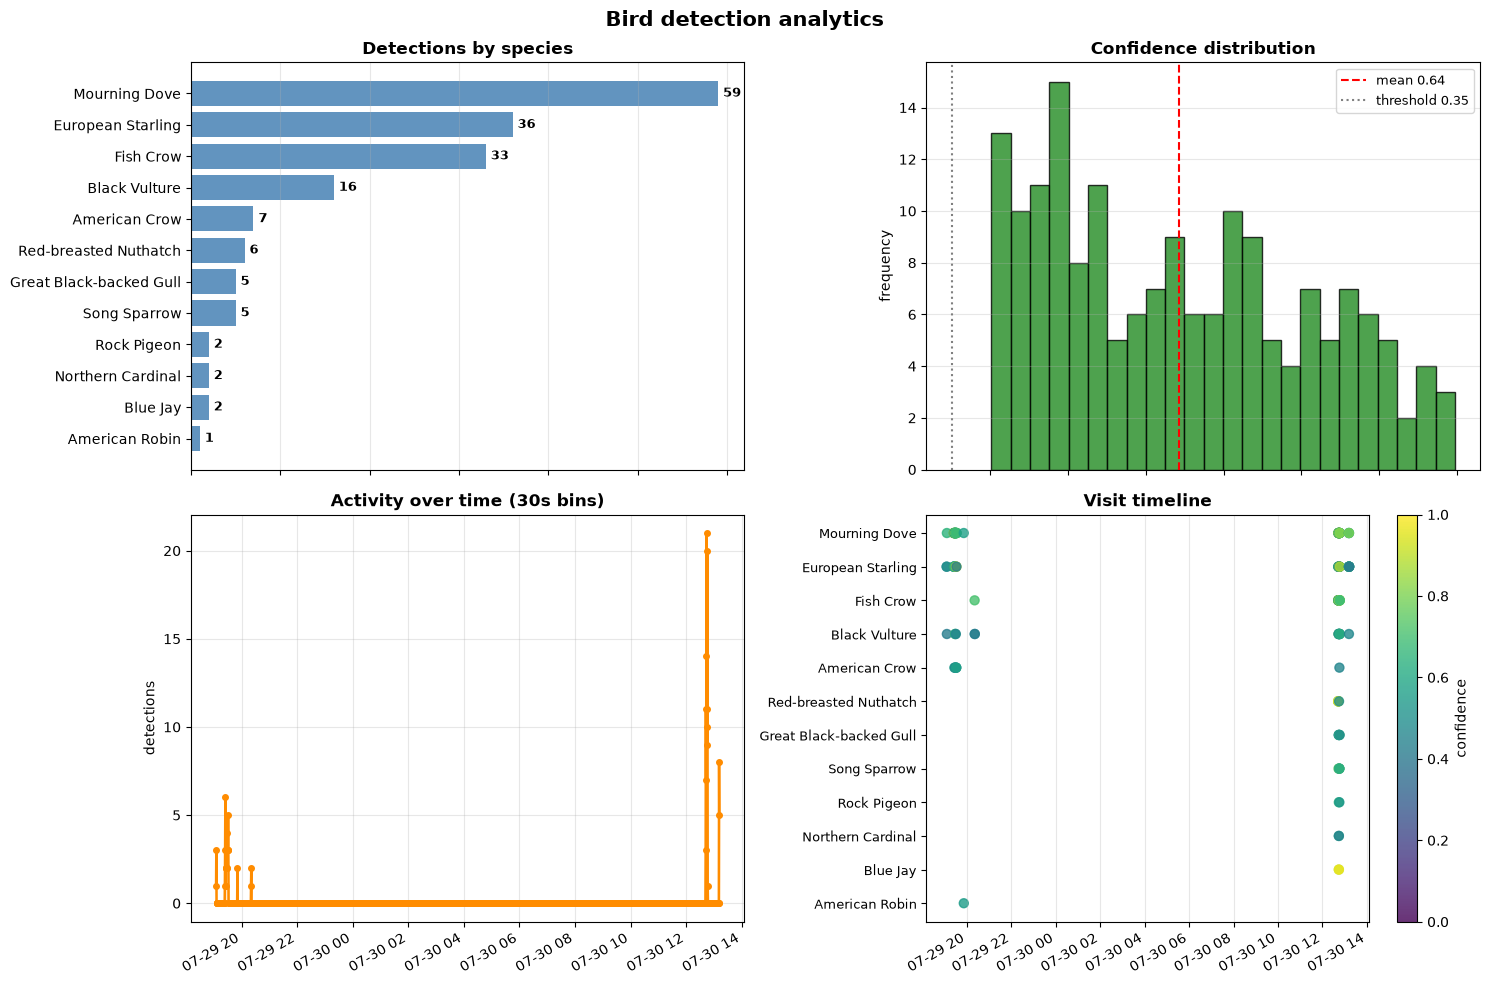

,species,count,avg_conf,best_conf,first_seen,last_seen
0,Mourning Dove,59,0.676919,0.948894,2026-07-29T19:05:46,2026-07-30T13:11:28
1,European Starling,36,0.593068,0.960490,2026-07-29T19:05:00,2026-07-30T13:11:59
2,Fish Crow,33,0.709595,0.997753,2026-07-29T20:20:44,2026-07-30T12:46:32
3,Black Vulture,16,0.528946,0.801183,2026-07-29T19:05:46,2026-07-30T13:11:24
4,American Crow,7,0.507747,0.587975,2026-07-29T19:26:09,2026-07-30T12:45:40
5,Red-breasted Nuthatch,6,0.788422,0.994465,2026-07-30T12:42:25,2026-07-30T12:44:38
6,Great Black-backed Gull,5,0.533681,0.679848,2026-07-30T12:43:52,2026-07-30T12:46:06
7,Song Sparrow,5,0.620928,0.753529,2026-07-30T12:43:11,2026-07-30T12:45:30
8,Blue Jay,2,0.917582,0.974016,2026-07-30T12:44:07,2026-07-30T12:44:12
9,Northern Cardinal,2,0.535054,0.626483,2026-07-30T12:44:07,2026-07-30T12:44:12


In [14]:
# ============================================================================
#  11. ANALYTICS DASHBOARD
# ============================================================================

def dashboard(db=None, bin_seconds=30):
    db = db or DB
    df = db.frame()
    if df.empty:
        print("No detections in the database yet. Run a live session first.")
        return df

    df["dt"] = pd.to_datetime(df["ts"], unit="s")
    span = df["ts"].max() - df["ts"].min()

    print("=" * 60)
    print(f"  detections     : {len(df)}")
    print(f"  species        : {df['species'].nunique()}")
    print(f"  span           : {span / 60:.1f} min "
          f"({df['dt'].min():%Y-%m-%d %H:%M} → {df['dt'].max():%H:%M})")
    print(f"  rate           : {len(df) / max(span, 1) * 60:.1f} logged/min")
    print(f"  confidence     : mean {df['confidence'].mean():.3f}  "
          f"median {df['confidence'].median():.3f}  max {df['confidence'].max():.3f}")
    print("=" * 60)

    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle("Bird detection analytics", fontsize=15, fontweight="bold")

    # 1 — who showed up
    counts = df["species"].value_counts().sort_values()
    ax = axes[0, 0]
    ax.barh(counts.index, counts.values, color="steelblue", alpha=.85)
    for i, v in enumerate(counts.values):
        ax.text(v, i, f" {v}", va="center", fontsize=9, fontweight="bold")
    ax.set_title("Detections by species", fontweight="bold")
    ax.set_xlabel("count")
    ax.grid(axis="x", alpha=.3)

    # 2 — how sure the model was
    ax = axes[0, 1]
    ax.hist(df["confidence"], bins=24, color="forestgreen", alpha=.8, edgecolor="black")
    ax.axvline(df["confidence"].mean(), color="red", ls="--",
               label=f"mean {df['confidence'].mean():.2f}")
    ax.axvline(CONF_THRESHOLD, color="grey", ls=":", label=f"threshold {CONF_THRESHOLD}")
    ax.set_title("Confidence distribution", fontweight="bold")
    ax.set_xlabel("confidence")
    ax.set_ylabel("frequency")
    ax.legend(fontsize=9)
    ax.grid(axis="y", alpha=.3)

    # 3 — activity over time
    ax = axes[1, 0]
    binned = df.set_index("dt").resample(f"{bin_seconds}s").size()
    ax.plot(binned.index, binned.values, marker="o", ms=4, lw=1.8, color="darkorange")
    ax.fill_between(binned.index, binned.values, alpha=.2, color="darkorange")
    ax.set_title(f"Activity over time ({bin_seconds}s bins)", fontweight="bold")
    ax.set_ylabel("detections")
    ax.grid(alpha=.3)
    fig.autofmt_xdate()

    # 4 — who was there, when
    ax = axes[1, 1]
    order = list(counts.index)
    ypos = {s: i for i, s in enumerate(order)}
    sc = ax.scatter(df["dt"], df["species"].map(ypos), c=df["confidence"],
                    cmap="viridis", s=42, alpha=.8, vmin=0, vmax=1)
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(order, fontsize=9)
    ax.set_title("Visit timeline", fontweight="bold")
    ax.grid(axis="x", alpha=.3)
    fig.colorbar(sc, ax=ax, label="confidence")

    plt.tight_layout()
    plt.show()

    display(db.counts_by_species())
    return df


ANALYTICS = dashboard()


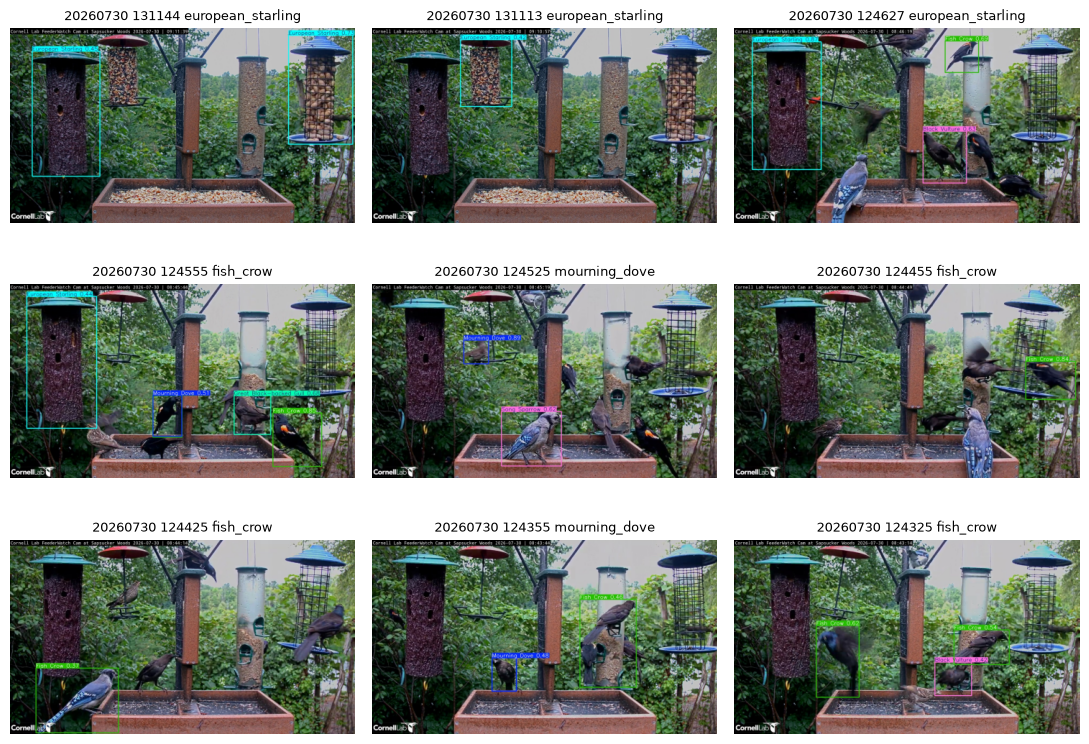

9 of 30 captures · /home/jovyan/bird_project/captures


In [15]:
# ============================================================================
#  12. CAPTURE GALLERY
# ============================================================================
# Rewritten to be un-hangable, and to say which file it is on if it ever does.
# Three changes from the version that stalled:
#
#   1. Each filename is printed BEFORE it is read. If the cell stops again you
#      will know exactly which frame did it instead of staring at a blank [*].
#   2. Frames are downscaled with cv2 before matplotlib sees them. Nine 1280x720
#      arrays inside tight_layout() is a lot of work for a thumbnail grid.
#   3. plt.close() on the way in and out, so figures do not accumulate across
#      re-runs of this cell.
#
# If it hangs with the kernel idle and no filename printed, the cell is not
# your problem — see the note under `gallery_html` below.
# ============================================================================

def show_captures(n=9, newest_first=True, max_px=480, verbose=False):
    files = sorted(CAPTURE_DIR.glob("*.jpg"), key=lambda p: p.stat().st_mtime,
                   reverse=newest_first)[:n]
    if not files:
        print(f"No captures in {CAPTURE_DIR}. "
              f"Set SAVE_FRAMES = True and run a live session.")
        return

    thumbs = []
    for path in files:
        if verbose:
            print(f"  reading {path.name}", flush=True)
        img = cv2.imread(str(path))
        if img is None:                       # truncated write, usually from an
            continue                          # interrupted live session
        scale = max_px / max(img.shape[:2])
        if scale < 1:
            img = cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
        thumbs.append((path, cv2.cvtColor(img, cv2.COLOR_BGR2RGB)))

    if not thumbs:
        print(f"{len(files)} files found but none decoded — all truncated?")
        return

    plt.close("all")
    cols = min(3, len(thumbs))
    rows = (len(thumbs) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4.6 * cols, 3.1 * rows))
    axes = np.atleast_1d(axes).ravel()

    for ax, (path, img) in zip(axes, thumbs):
        ax.imshow(img)
        ax.set_title(path.stem.replace("_", " ", 2), fontsize=9)
        ax.axis("off")
    for ax in axes[len(thumbs):]:
        ax.axis("off")

    fig.subplots_adjust(hspace=.25, wspace=.05)
    plt.show()
    plt.close(fig)
    print(f"{len(thumbs)} of {len(list(CAPTURE_DIR.glob('*.jpg')))} captures · {CAPTURE_DIR}")


def gallery_html(n=9, max_px=360):
    """
    Matplotlib-free fallback. Encodes thumbnails to base64 and hands the
    browser plain <img> tags.

    Reach for this if the notebook front end feels wedged rather than the
    kernel — the usual cause is the live view, which pushes one JPEG per
    refresh into the output area. Five minutes at 4 fps is ~1200 image
    payloads in a single cell; the kernel finishes fine and the tab is what
    stops repainting. Clearing that cell's output (Cell > Current Outputs >
    Clear) usually brings everything back at once.
    """
    import base64
    files = sorted(CAPTURE_DIR.glob("*.jpg"), key=lambda p: p.stat().st_mtime,
                   reverse=True)[:n]
    if not files:
        print(f"No captures in {CAPTURE_DIR}.")
        return
    tiles = []
    for path in files:
        img = cv2.imread(str(path))
        if img is None:
            continue
        scale = max_px / max(img.shape[:2])
        if scale < 1:
            img = cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
        ok, buf = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 75])
        if not ok:
            continue
        b64 = base64.b64encode(buf.tobytes()).decode()
        tiles.append(
            f"<figure style='margin:0'>"
            f"<img src='data:image/jpeg;base64,{b64}' style='width:100%;border-radius:4px'>"
            f"<figcaption style='font:11px ui-monospace,Menlo,monospace;opacity:.7;"
            f"padding-top:3px'>{path.stem}</figcaption></figure>")
    display(HTML(
        "<div style='display:grid;grid-template-columns:repeat(3,1fr);gap:10px'>"
        + "".join(tiles) + "</div>"))


show_captures()


## Quick reference

### Knobs you will reach for most

| Setting | Effect |
|---|---|
| `PIPELINE_MODE` | `auto` reuses everything already on disk · `force` rebuilds all of it · `ask` prompts per stage. |
| `FORCE_STAGES` | Rerun just these, e.g. `{"train"}`. Names: `species`, `download`, `dataset`, `train`, `live`. |
| `SKIP_STAGES` | Never run these, e.g. `{"live"}` for an offline analysis pass. |
| `STREAM_OUT` | Where the annotated frames go: `["mjpeg"]`, `["hls"]`, `["mjpeg","rtmp"]`, `[]` for off. |
| `STREAM_OUT_FPS` | Cadence given to viewers. Frames repeat when inference is slower, so the rate is real. |
| `MJPEG_PORT` / `HLS_PORT` | Where to point a browser. `MJPEG_BIND = "127.0.0.1"` keeps it off the network. |
| `LIVE_REFRESH_FPS` | Detect + redraw cycles per second. `2` is easy on the GPU, `8`–`10` feels like video. |
| `LIVE_MAX_MINUTES` | Auto-stop. Interrupt the kernel to stop sooner. |
| `CONF_THRESHOLD` | Boxes drawn. Too many false hits → raise it. Missing obvious birds → lower it. |
| `DB_COOLDOWN_SECONDS` | Rows per species per window. This is the main "don't save so much" dial. |
| `SPECIES_MODE` / `SPECIES_MANUAL` | Which birds you train on. |
| `FRAME_COOLDOWN_SECONDS` / `FRAME_MAX_FILES` | How many annotated JPEGs pile up. |

### Re-running without redoing everything

```python
RUN_FETCH_SPECIES = False
RUN_DOWNLOAD      = False
RUN_BUILD_DATASET = False
RUN_TRAIN         = False
RUN_LIVE          = True
```

The species list, taxon IDs, raw photos and trained weights all persist under
`bird_project/`, so this drops you straight into the live view. You can also
override per-run without touching the panel:

```python
DB = run_live(minutes=1, refresh_fps=8, conf=0.25)
```

### Empty database — what to check, in order

1. **Did the video pane actually move?** No → stream. Re-run `preflight()`;
   a resolved URL that OpenCV cannot open usually means the link expired
   (`STREAM_RECONNECT = True` handles this during a run) or your OpenCV was
   built without FFmpeg/HLS.
2. **Video moved but no boxes?** Detection. Drop `CONF_THRESHOLD` to `0.1`
   and re-run `preflight()` — it prints box counts at six thresholds, so you
   can see whether the model is finding *anything*.
3. **Boxes drawn but nothing logged?** Throttling. Lower `DB_MIN_CONFIDENCE`
   and `DB_COOLDOWN_SECONDS`.
4. **Species names look like `person`, `car`, `dog`?** You are on the stock
   COCO model — the header printed at the start of `run_live()` says so
   explicitly. Train, or point `MODEL_PATH_OVERRIDE` at real weights.

### Stopping the live session

```bash
touch bird_project/STOP        # from a terminal — the reliable one
```

Interrupting the kernel also works and prints the same summary. What cannot
work is a widget stop button: Jupyter runs one cell at a time, and while
`run_live()` is looping it holds the kernel's event loop, so no callback —
button, timer, or otherwise — will ever fire. That is why the stop signal is
a file.

If a session ever ends without printing, its reader thread may still be alive
and holding the stream. `stop_live()` reaps it, and `run_live()` calls that
automatically before starting, so re-running the cell is safe.

The summary is written to **both** stdout and the widget, because Jupyter can
drop buffered stdout when a cell is interrupted mid-flush. If the printed
block is missing, the same text appears under the video.

### "Is it actually using the GPU?"

Run `gpu_status()` in a second cell while training is going. It prints
`torch.cuda.is_available()`, `torch.version.cuda`, allocated/reserved memory
and live `nvidia-smi` utilisation. The training cell also reports the device
its parameters ended on and peak GPU memory — a real GPU run never shows
0.00 GB.

Two failure modes look identical from the outside and are not:

- **Actually on CPU.** `torch.cuda.is_available()` is False. On ARM64 the usual
  cause is a CPU-only PyTorch wheel; `pip install torch torchvision --index-url
  https://download.pytorch.org/whl/cu130`, then restart the kernel.
- **On the GPU but starved.** Utilisation bounces near zero, CPU pegged, epochs
  crawl. This is dataloader-bound, not compute-bound. `TRAIN_CACHE = "ram"` and
  `TRAIN_WORKERS` are the fix — with 128 GB unified memory there is no reason
  to re-decode JPEGs every epoch.

One reliable tell: Ultralytics' AMP check runs **only on CUDA**. If you see
`AMP: running Automatic Mixed Precision (AMP) checks` and a small stock
checkpoint downloading at the start of training, PyTorch found the GPU. If
training begins without it, you are on CPU.

A `cuda capability 12.1 ... supported is (8.0) - (12.0)` UserWarning on GB10 is
cosmetic — kernels still run.

### Where the surprise model download comes from

Ultralytics runs that AMP check at the start of every CUDA training run, and it
loads a small stock checkpoint — currently `yolo26n.pt` — regardless of which
base model you chose. One-time ~6 MB, cached, unrelated to your dataset.

The other source is `resolve_model_path()` falling through to its stock-model
fallback when no trained weights exist yet, which the cell announces in plain
text before it happens.

### Training quality

A feeder cam is a hard target: small, partly hidden, motion-blurred birds at a
fixed angle, while iNaturalist photos are large, sharp and centred. Expect the
first model to be optimistic on paper and mediocre on the actual stream. Two
things move the needle far more than extra epochs:

- **Fewer, better-separated classes.** Ten distinctive feeder regulars beats
  thirty species where six are near-identical sparrows.
- **Frames from your own camera.** Once a session has run, `bird_project/captures/`
  holds real frames from the exact angle and lighting you care about. Correcting
  a few dozen of those and folding them into `dataset/raw/` is worth more than
  another thousand iNaturalist photos.

`REQUIRE_BIRD_BOX = True` matters here too. With it off, any photo where the
auto-labeller found nothing gets a full-frame box, teaching the model that
"bird" means "the entire image" — which is exactly the kind of label noise
that produces confident nonsense on a live feed.

### Photo licensing

`INAT_LICENSED_ONLY = True` restricts downloads to CC-licensed photos, and each
species folder gets an `_attribution.csv` naming the photographer and licence.
Worth keeping if this ever leaves your machine — several CC variants require
attribution, and iNaturalist's default is all-rights-reserved.


### Re-running without paying for it twice

The pipeline is now self-aware about its own outputs. On a warm project,
Run All reaches the live view in seconds — the eBird list, the iNaturalist
photos, the train/val split and `best.pt` are all reused, and the stock COCO
checkpoint the auto-labeller needs is never fetched, because that stage never
loads.

Each stage prints its decision and the reason for it:

```
SKIP ✓  species   12 species cached, 3.2d old
SKIP ✓  download  681 labelled photos, 11/12 species above minimum
SKIP ✓  dataset   11 classes, 545 train / 136 val
SKIP ✓  train     11 classes, trained 3.1d ago, mAP50 0.612
RUN  ▶  live      a live session is never cached
```

Stages turn themselves back on when the thing they depend on changes:

| You change | What reruns |
|---|---|
| `MAX_SPECIES`, or the cache passes `SPECIES_CACHE_MAX_AGE_DAYS` | species → download → dataset → train |
| `SPECIES_MANUAL`, `SPECIES_MODE` | download → dataset → train |
| `IMAGES_PER_SPECIES` (upward), `REQUIRE_BIRD_BOX`, `INAT_LICENSED_ONLY` | download → dataset → train |
| new photos land in `dataset/raw/` | dataset → train |
| `TRAIN_BASE_MODEL`, or the class list no longer matches `best.pt` | train |
| `TRAIN_EPOCHS`, `TRAIN_IMGSZ`, `TRAIN_BATCH` | nothing — set `FORCE_STAGES = {"train"}` |

That last row is deliberate. Hyperparameters do not invalidate a model the way
a changed class list does, so bumping epochs is treated as a preference rather
than a correctness problem — say so explicitly when you want it acted on.

Two files carry the state:

- `cache/download_state.json` — what the last download pass asked for. This is
  why a species that only had 30 usable photos does not trigger a fresh
  download every run: the notebook knows it already asked.
- `models/best.meta.json` — the class list, base model and mAP50 behind
  `best.pt`. Written after training; back-filled from an existing checkpoint
  the first time you run this version. It is what lets the train gate compare
  weights against a dataset without loading either.

Delete either file to force that stage. Delete `bird_project/` to start over.


### Streaming the annotated view out of the notebook

`STREAM_OUT` decides where the boxes-and-labels frames go. Several at once is
fine — MJPEG for yourself while RTMP feeds a platform.

**`["mjpeg"]` — the default, and probably where to stop.** A tiny threaded HTTP
server hands out `multipart/x-mixed-replace` JPEGs. Open
`http://<this-box>:8089/` and it plays; drop
`<img src="http://<this-box>:8089/stream.mjpg">` into any page and it plays
there too. No ffmpeg, no player library, no manifest, latency of one inference
interval. `/snapshot.jpg` gives you a single current frame, which is handy for
digital signage that would rather poll than hold a connection.

Its limits are real but rarely bite at feeder-cam scale: bandwidth is linear in
viewers because every one of them gets their own JPEGs, there is no audio and no
seeking, and browsers cap concurrent connections per host at around six — each
open MJPEG stream permanently holds one.

**`["hls"]` — when you want many viewers or a recording.** ffmpeg encodes to
H.264 and writes rolling segments into `bird_project/stream/`, and a static
server publishes them with the right MIME types and CORS headers.
`http://<this-box>:8090/` serves a player page that uses native HLS on
Safari/iOS and hls.js elsewhere. Expect 3-6 seconds behind live: 1-second
segments and a player that keeps a couple in hand. `HLS_SEGMENT_SECONDS` and
`HLS_WINDOW` are the knobs, and there is a floor you cannot tune past — plain
HLS is a segmented format.

**`["rtmp"]`** with `RTMP_URL = "rtmp://a.rtmp.youtube.com/live2/<key>"` puts it
on YouTube. Bear in mind what you are publishing: iNaturalist photos trained the
model, but the frames are Cornell's stream with your overlay, so check their
terms before making it public.

**`["rtsp"]` — lowest latency, least code.** Run
[MediaMTX](https://github.com/bluenviron/mediamtx) alongside the notebook: one
Go binary, no config needed for this. Set
`RTSP_URL = "rtsp://127.0.0.1:8554/birds"` and it republishes the same stream as
WebRTC at `http://<this-box>:8889/birds` (sub-second, many viewers), HLS at
`http://<this-box>:8888/birds/index.m3u8`, and RTSP for VLC. This is the option
to pick if MJPEG runs out of headroom.

#### Things that will bite you

`STREAM_OUT_FPS` is independent of `LIVE_REFRESH_FPS`. A pacer thread feeds
ffmpeg at a constant rate and repeats the last frame when detection is slower,
which is deliberate: it keeps the `-r` handed to ffmpeg truthful, so HLS segment
durations and RTMP timestamps do not drift. Duplicate frames of a mostly-static
feeder cost x264 almost nothing.

Nothing in the broadcast path can block inference. Writes go into a one-slot
buffer; if a viewer stalls or an upload backs up, frames are dropped rather than
queued, and the detector never notices.

When ffmpeg dies it says why in `bird_project/ffmpeg_<mode>.log`. From the
notebook, `_ACTIVE["sinks"].sinks[0].tail()` prints the last dozen lines — read
that before changing anything else.

`Address already in use` after an interrupt means a previous server is still
holding the port. `stop_live()` reaps it. On a university network, `MJPEG_BIND`
defaults to `0.0.0.0`, so anyone who can route to the box can watch — set it to
`127.0.0.1` and use an SSH tunnel if that is not what you want.


### Viewing it from a JupyterLab container

`lan_ip()` reports the container's address on the Docker bridge — something
like `172.17.0.5`. That is a real address, but only the Docker host can route
to it. Your laptop cannot, which is why the printed URL does nothing. Three
ways out, cheapest first:

**Tunnel through the Docker host.** Works right now, nothing to restart, since
the host *can* reach the bridge:

```bash
ssh -N -L 8089:172.17.0.5:8089 you@<docker-host>
# then open http://localhost:8089/
```

**Publish the port.** The permanent fix, but it means recreating the container:

```bash
docker run ... -p 8888:8888 -p 8089:8089 -p 8090:8090 ...
```

**Install `jupyter-server-proxy`.** The tidiest answer for a JupyterLab image,
because it reuses the port Jupyter is already published on and inherits its
auth and TLS — no second exposed port at all:

```bash
pip install jupyter-server-proxy      # then restart the Jupyter server
```

The stream then lives at `<your JupyterLab URL>/proxy/8089/`. Both built-in
pages use relative links specifically so they work under a path prefix like
that. Note the restart kills running kernels, so do it between sessions.

To confirm the server itself is fine before blaming the network, from a
terminal inside the container:

```bash
curl -s -o /dev/null -w '%{http_code}\n' http://127.0.0.1:8089/
```

`200` means the sink is working and everything left is a routing problem.

### The live view, and why it defaults to still frames

`LIVE_VIEW` is `"still"` out of the box. That path replaces a display handle
each frame and needs nothing installed — JupyterLab, Notebook 7, VS Code and
Colab all render it. At 4 fps you cannot tell it from the widget.

`LIVE_VIEW = "widget"` uses ipywidgets, which is smoother at higher refresh
rates but needs a frontend extension matching your ipywidgets version. When
that extension is missing it does not raise an error — it prints
`VBox(children=(Image(value=b'', ...)))` and shows no video, which looks like
the pipeline broke when in fact only the display did. `"auto"` checks for the
frontend packages first and falls back to stills, and says so when it does.

If you want the widget and it is not rendering:

```bash
pip list | grep -Ei 'ipywidgets|jupyterlab|widgetsnbextension'
pip install -U ipywidgets jupyterlab_widgets
```

Then restart the kernel **and** hard-reload the browser tab. The stale frontend
is cached, and skipping the reload is the usual reason this looks like it did
not work.

### `[tls @ 0x...] IO error: End of file`

FFmpeg's TLS layer, underneath OpenCV's `VideoCapture` — the inbound YouTube
read, not the outbound stream and not `LIVE_MAX_MINUTES`. The far end closed
the connection, which is normal after some minutes on a signed googlevideo URL.

The imports cell now sets two environment variables to deal with it:

```python
os.environ.setdefault("OPENCV_FFMPEG_CAPTURE_OPTIONS",
    "reconnect;1|reconnect_streamed;1|reconnect_on_network_error;1"
    "|reconnect_delay_max;5")
os.environ.setdefault("OPENCV_FFMPEG_LOGLEVEL", "8")
```

The first makes FFmpeg reopen the HTTP connection itself, so OpenCV never sees
a failed read and the ~5-second gap while `FrameGrabber` notices and
re-resolves the URL disappears. `reconnect_streamed` is the load-bearing one:
a live stream is not seekable, and plain `reconnect` will not retry it. The
second quiets messages that are written from C straight to stderr, where Python
logging cannot reach them.

Both use `setdefault`, so anything exported outside the notebook wins, and both
are read when a capture opens — set them before the live cell, not during.

If the stream genuinely stops rather than hiccuping, raise `OPENCV_FFMPEG_LOGLEVEL`
to `24` and re-run to get FFmpeg's own account of it. The reconnect count in the
live stats panel and the session summary tell you whether recovery is happening
at all.

### Handing this to someone else

Two things to change before you do. `EBIRD_API_KEY` now reads the environment
first and falls back to the key written into the Control Panel — eBird
rate-limits per key, so a class sharing one throttles itself; everyone should
get their own free key. And `INAT_USER_AGENT` should carry a real contact
address, which is what iNaturalist asks of API clients. The Control Panel warns
about both when it runs.

Beyond that the notebook is safe to hand over as-is: every stage decides for
itself whether it needs to run, so a student who hits Run All on a warm
`bird_project/` gets the live view in seconds rather than a twenty-minute
download-and-train they did not ask for, and one starting from an empty folder
gets the whole pipeline without editing anything.
